# LoRA adapter caching, milestone 2: trace replay with predictive prefetching
**CSCI 5144 Cloud Computing, Fall 2026.** Quenton Ni, Theo Nguyen, Sudeep Srisailapu, Tien Cao

Milestone 1 showed that **one** avoided adapter miss saves about 8 ms of time-to-first-token (TTFT), about 78 → 70 ms,
on an L4. That was a best case: the prefetch knew which adapter came next, there was a guaranteed idle gap,
and requests ran one at a time.

This notebook adds those three complications back and asks the proposal's question:

> **Under what workload conditions does predictive LoRA prefetching beat vLLM's reactive LRU caching, and when do
> prediction errors and prefetch overhead outweigh the benefit?**

| Part | What it does | Runs on | Time |
|---|---|---|---|
| 1. Setup | Workspace, GPU check, install vLLM 0.32.0, configuration | CPU/GPU | 3–5 min the first time |
| 2. Workloads | Synthetic generator with five independent factors, plus a real Azure Functions 2021 trace | CPU | < 1 min |
| 3. Policies | LRU (baseline), EWMA prefetch, EWMA + cost-aware admission, with unit checks | CPU | seconds |
| 4. CPU simulator | Count-only replay over many seeds and parameter sweeps, as a pre-GPU expectation | CPU | ~1 min |
| 5. GPU harness and milestone-1 replication | In-process vLLM engine, residency probe, the paired single-miss experiment again | GPU | ~3 min |
| 6. GPU trace replay | Every scenario × policy × slot count, with concurrent requests | GPU | ~35 min (full) / ~8 min (quick) |
| 7. Results | Validity checks, tables, figures, auto-written findings | CPU | seconds |
| 8. Presenting | Suggested slide order, limitations, next steps, export | n/a | n/a |

**How to run:** in Colab, choose **Runtime → Change runtime type → GPU (L4 preferred)**, then **Runtime → Run all**.
For a fast smoke test, set `QUICK_MODE = True` in the configuration cell first.
Without a GPU, Parts 1–4 still run; the GPU cells print a skip message.

### What changed since milestone 1
| | Milestone 1 | Milestone 2 (this notebook) |
|---|---|---|
| vLLM | 0.11.0, `AsyncLLM` in a separate subprocess | **0.32.0**, `LLMEngine` stepped **in the notebook process** |
| Code layout | Cells wrote `lab_utils.py`, `residency_probe.py`, `run_experiment.py`, then ran them | **All code lives in cells**; nothing is written to `.py` files |
| Adapters / slots | 3 adapters, 2 GPU slots | **8 adapters, 2 and 4 GPU slots** (proposal §4.1) |
| Concurrency | One request at a time (`max_num_seqs=1`) | **Up to 16 concurrent requests**, timestamped arrivals |
| Who decides to prefetch | The experimenter (knew C was next) | **Predictors that only see past requests** |
| Workload | One toy trace (A-heavy, then C-heavy) | **Generator with burstiness, skew, locality, abrupt/gradual drift** + **Azure Functions 2021** |
| Metrics | TTFT of one request | TTFT p50/p95/p99, hit rate, demand loads, useful/wasted prefetches, wasted bytes, evictions, drift recovery |

**Why milestone 1 wrote `.py` files, and why this notebook doesn't need to.** vLLM's async engine runs the scheduler
and GPU worker in a separate process. Code that observes the worker, the residency probe, had to be importable
*by module name* in that process, so it had to live in a file. Running the experiment as a subprocess also
kept a CUDA crash from killing the notebook.

vLLM can instead run its engine core **in-process** (`VLLM_ENABLE_V1_MULTIPROCESSING=0`). The notebook then calls
`engine.step()` itself, so the probe is an ordinary Python object attached to the live LoRA manager, and the
replay loop controls time exactly. There is one trade-off: if CUDA crashes or runs out of memory, use **Runtime → Restart session**,
then re-run from the top. Results are saved to disk after every run, so nothing completed is lost.

## Background and key terms
Use this section as the "setup" slide.

| Term | Meaning in this project |
|---|---|
| **LoRA adapter** | Small low-rank weight deltas (here rank 8 on `q_proj` and `v_proj`, about 2.2 MB in fp16) that customise one shared base model. |
| **CPU cache** | All 8 adapters are kept in host memory (`max_cpu_loras=8`), so **no disk loads** happen during measurements. |
| **GPU slot** | vLLM keeps at most `max_loras` adapters on the GPU. We test **2 and 4 slots** for 8 adapters, which creates cache pressure. `max_loras` also caps how many *distinct* adapters can share one batch. |
| **Activation** | Copying an adapter from the CPU cache into a GPU slot. With full slots, vLLM's **LRU** evicts the least recently used adapter. |
| **Demand load (miss)** | An activation that happens *inside* an engine step because a scheduled request needs the adapter. The whole batch waits for it. |
| **Prefetch** | An activation the predictor triggers *between* steps through vLLM's own `add_lora()` API. vLLM still picks the victim by LRU (proposal §4.3). |
| **Touch** | `add_lora()` on an adapter that is already resident. Nothing is copied; it only moves the adapter to the "most recently used" end. The admission policy uses this to protect hot adapters. |
| **Useful / wasted prefetch** | Useful: an engine step used the prefetched adapter before it was evicted. Wasted: it was evicted, or the run ended, first. |
| **Prefetch-induced load** | A demand load of an adapter within 2 s of a prefetch evicting it: a wrong guess that pushed out something still needed. |
| **TTFT** | Time from a request's **scheduled arrival** in the trace to its first output token. It includes queueing, so it is what a user would feel. |
| **Hit at arrival** | The request's adapter was already on the GPU when the request arrived. This is the quantity prefetching tries to raise. |

**The three policies** (Part 3 has the details):
1. **LRU**: vLLM's default. It loads adapters only on demand and never prefetches.
2. **EWMA**: estimates each adapter's request rate with an exponentially weighted moving average and keeps the top-*k*
   (k = number of slots) adapters resident by prefetching them. It has no cost checks.
3. **EWMA+admission**: the same prediction, but each prefetch must pass four cost rules: idle victim, enough expected benefit,
   not busy, and within a transfer budget (proposal §4.4).

---
# Part 1: Setup
### 1.1 Workspace and GPU check
This cell uses only the Python standard library. Every execution of the notebook creates a new timestamped results folder
under `lora_cache_lab/results/`. All CSVs, figures and the findings file go there.

In [1]:
# Standard-library only, so this cell is safe to run before anything is installed.
import gc
import json
import math
import os
import random
import shutil
import subprocess
import sys
import time
import zipfile
from collections import Counter, OrderedDict, defaultdict, deque
from datetime import datetime, timezone
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
LAB = (Path('/content') if Path('/content').is_dir() else Path.cwd()) / 'lora_cache_lab'
LAB.mkdir(parents=True, exist_ok=True)
RUN_DIR = LAB / 'results' / ('m2_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ'))
FIG_DIR = RUN_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)


def nvidia_smi_summary():
    """Return 'name, memory, driver' for the GPU, or None when there is no NVIDIA GPU."""
    exe = shutil.which('nvidia-smi')
    if not exe:
        return None
    out = subprocess.run([exe, '--query-gpu=name,memory.total,driver_version', '--format=csv,noheader'],
                         text=True, capture_output=True)
    return out.stdout.strip() if out.returncode == 0 and out.stdout.strip() else None


GPU_SUMMARY = nvidia_smi_summary()
HAS_GPU = GPU_SUMMARY is not None
print('Workspace :', LAB)
print('This run  :', RUN_DIR)
print('Python    :', sys.version.split()[0], '| Colab:', IN_COLAB)
print('GPU       :', GPU_SUMMARY or 'none detected. GPU parts (5-6) will be skipped; CPU parts still run')

Workspace : /content/lora_cache_lab
This run  : /content/lora_cache_lab/results/m2_20261102T221446Z
Python    : 3.13.16 | Colab: True
GPU       : NVIDIA L4, 23034 MiB, 580.82.07


### 1.2 Install vLLM 0.32.0
Milestone 1 pinned vLLM 0.11.0. This notebook moves to **0.32.0** (released 2026-10-18). We pin an exact version
because the residency probe touches vLLM internals. Before choosing 0.32.0 we read its source and confirmed:

* The LoRA slot cache is still `LRUCacheLoRAModelManager`, with `activate_adapter`, `deactivate_adapter`,
  `lora_index_to_id` and an LRU `_active_adapters` cache whose `.order` gives oldest → newest.
* Every engine step still activates the batch's adapters through `LRUCacheWorkerLoRAManager.set_active_adapters`.
* `add_lora()` on an adapter already in the CPU cache **activates it on the GPU**, which is our prefetch path.
  0.32 also explicitly supports an "out-of-band `add_lora()` that LRU-evicts and reassigns slots while a batch is
  running": `set_adapter_mapping` now re-checks the slot layout. That is exactly the prefetch-under-load case.
* `LLMEngine` with `VLLM_ENABLE_V1_MULTIPROCESSING=0` runs the engine core in-process, and `step()` drives it.

0.33.0 came out the day this notebook was written and was deliberately **not** used. Installing vLLM also installs
its pinned PyTorch (2.13) into the Colab runtime. `pip freeze` is saved with the results.

In [2]:
VLLM_VERSION = '0.32.0'


def installed_version(package):
    from importlib.metadata import PackageNotFoundError, version
    try:
        return version(package)
    except PackageNotFoundError:
        return None


if not HAS_GPU:
    print('No GPU, so vLLM is not installed. The CPU-only parts (2-4) still run.')
elif installed_version('vllm') == VLLM_VERSION:
    print(f'vLLM {VLLM_VERSION} already installed; skipping.')
else:
    print(f'Installing vLLM {VLLM_VERSION} and its pinned PyTorch. This takes a few minutes...')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', f'vllm=={VLLM_VERSION}'], check=True)
    print('Done. If a later cell fails with a NumPy/PyTorch binary-compatibility error, use '
          'Runtime → Restart session and run the notebook from the top (this cell will then skip itself).')

Installing vLLM 0.32.0 and its pinned PyTorch. This takes a few minutes...
Done. If a later cell fails with a NumPy/PyTorch binary-compatibility error, use Runtime → Restart session and run the notebook from the top (this cell will then skip itself).


### 1.3 Analysis libraries and plotting style
These are already in Colab. Every figure uses the same colour per policy, so slides read consistently.

In [3]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

pd.set_option('display.width', 180)
pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'font.size': 10})

POLICY_COLORS = {'LRU': '#6b7280', 'EWMA': '#d97706', 'EWMA+admission': '#2563eb'}
POLICY_ORDER = list(POLICY_COLORS)


def savefig(fig, name):
    """Save a figure as PNG in this run's figures folder, then display it."""
    path = FIG_DIR / f'{name}.png'
    fig.savefig(path, dpi=160, bbox_inches='tight')
    print('saved figure:', path.relative_to(LAB))
    plt.show()


print('numpy', np.__version__, '| pandas', pd.__version__, '| matplotlib', matplotlib.__version__)

numpy 2.4.6 | pandas 2.2.3 | matplotlib 3.10.0


### 1.4 Experiment configuration
Everything that changes a result is in this one dictionary, which is saved as `config.json` next to the results.
Choices that differ from milestone 1 are commented. If you change something, re-run from this cell down.

The arrival rate (4 req/s on average) is meant to give a **moderately loaded** L4: requests overlap, bursts queue,
but the engine is not saturated. Part 6 starts with a short **load check** and warns you if that assumption fails.

In [4]:
QUICK_MODE = False   # True = smoke test: 20 s traces, 3 scenarios, 2 slots only (~8 min of GPU time)

CONFIG = {
    # ---- Model and serving (same base model and adapter shape as milestone 1) ----
    'model_id': 'Qwen/Qwen2.5-1.5B-Instruct',
    'revision': 'main',               # resolved to an exact commit hash at run time and recorded
    'vllm_version': VLLM_VERSION,
    'n_adapters': 8,                  # proposal §4.1: eight equal-rank adapters
    'rank': 8,
    'slot_configs': [2, 4],           # GPU LoRA slots (vLLM max_loras). One engine per value.
    'max_num_seqs': 16,               # concurrent sequences per batch (milestone 1 used 1)
    'max_num_batched_tokens': 2048,
    'max_model_len': 512,
    'gpu_memory_utilization': 0.40,   # low on purpose: a second engine must fit after the first shuts down
    'prompt_tokens': 64,
    'output_tokens': 16,
    'seed': 7,
    # ---- Part 5: milestone-1 replication (paired single-miss diagnostic, needs 2 slots) ----
    'diag_repeats': 20,               # milestone 1 used 10
    'diag_gap_s': 0.30,
    'diag_prefetch_offset_s': 0.05,
    # ---- Part 2: workloads ----
    'duration_s': 45.0,               # length of every replayed trace
    'mean_rate': 4.0,                 # requests per second, averaged over the trace
    'scenarios': ['uniform_steady', 'skewed_steady', 'skewed_bursty', 'skewed_local',
                  'drift_abrupt', 'drift_gradual', 'azure_2021'],
    # ---- Part 3: policies ----
    'tick_s': 0.25,                   # predictors update (and may prefetch) every tick
    'ewma_alpha': 0.10,               # per-tick smoothing; time constant ≈ tick_s / alpha = 2.5 s
    'min_rate': 0.05,                 # req/s; never prefetch an adapter the EWMA has (almost) never seen
    'admit_horizon_s': 2.0,           # R2 looks this far ahead
    'admit_min_net_hits': 0.5,        # R2: need ≥ this many more expected requests for candidate than victim
                                      #     (0.5 chosen from the simulator trade-off in Part 4.4)
    'admit_max_inflight': 4,          # R3: no speculative load when more requests than this are in flight
    'admit_max_prefetch_per_s': 2.0,  # R4: token-bucket budget for speculative loads
    # ---- Part 4: CPU simulator ----
    'sim_seeds': 20,
    'sim_service_s': 0.4,             # the simulator treats a request as "in flight" for this long
    # ---- Part 2b: Azure Functions 2021 trace ----
    'azure_url': 'https://raw.githubusercontent.com/Azure/AzurePublicDataset/master/data/'
                 'AzureFunctionsInvocationTraceForTwoWeeksJan2021.rar',
    'azure_window_s': 180.0,          # this much of the real trace is time-compressed into duration_s
    'azure_window_start_s': None,     # None = auto-select a representative window (Part 2b)
    'quick_mode': QUICK_MODE,
}
if QUICK_MODE:
    CONFIG.update(duration_s=20.0, slot_configs=[2], diag_repeats=8, sim_seeds=8,
                  scenarios=['skewed_bursty', 'drift_abrupt', 'azure_2021'])

assert CONFIG['prompt_tokens'] + CONFIG['output_tokens'] <= CONFIG['max_model_len']
assert all(1 <= s < CONFIG['n_adapters'] for s in CONFIG['slot_configs']), 'need fewer slots than adapters'
ADAPTER_IDS = list(range(1, CONFIG['n_adapters'] + 1))
(RUN_DIR / 'config.json').write_text(json.dumps(CONFIG, indent=2))
print(json.dumps(CONFIG, indent=2))

{
  "model_id": "Qwen/Qwen2.5-1.5B-Instruct",
  "revision": "main",
  "vllm_version": "0.32.0",
  "n_adapters": 8,
  "rank": 8,
  "slot_configs": [
    2,
    4
  ],
  "max_num_seqs": 16,
  "max_num_batched_tokens": 2048,
  "max_model_len": 512,
  "gpu_memory_utilization": 0.4,
  "prompt_tokens": 64,
  "output_tokens": 16,
  "seed": 7,
  "diag_repeats": 20,
  "diag_gap_s": 0.3,
  "diag_prefetch_offset_s": 0.05,
  "duration_s": 45.0,
  "mean_rate": 4.0,
  "scenarios": [
    "uniform_steady",
    "skewed_steady",
    "skewed_bursty",
    "skewed_local",
    "drift_abrupt",
    "drift_gradual",
    "azure_2021"
  ],
  "tick_s": 0.25,
  "ewma_alpha": 0.1,
  "min_rate": 0.05,
  "admit_horizon_s": 2.0,
  "admit_min_net_hits": 0.5,
  "admit_max_inflight": 4,
  "admit_max_prefetch_per_s": 2.0,
  "sim_seeds": 20,
  "sim_service_s": 0.4,
  "azure_url": "https://raw.githubusercontent.com/Azure/AzurePublicDataset/master/data/AzureFunctionsInvocationTraceForTwoWeeksJan2021.rar",
  "azure_window_s":

---
# Part 2: Workloads
### 2.1 Synthetic workload generator
Proposal §4.2 asks us to vary five factors **independently**. Each one is a separate generator argument:

| Factor | Argument | Model |
|---|---|---|
| **Arrival pattern** | `burst` | `None` = Poisson arrivals at `mean_rate`. Otherwise a two-state on/off process: "on" periods run `on_mult`× faster than "off" periods, with exponential on/off lengths. The overall mean rate is unchanged, so only burstiness varies. |
| **Popularity skew** | `zipf_s` | P(adapter of rank *k*) ∝ 1/*k*^s. s = 0 is uniform; s = 1.2 sends ~43% of requests to the top adapter when there are 8. |
| **Temporal locality** | `locality` | With probability `p_repeat`, reuse one of the last `window` adapters instead of drawing from the popularity distribution, which shortens reuse distance. |
| **Cache capacity** | (not here) | Set by `slot_configs`, so every trace is replayed at 2 and 4 slots. |
| **Drift** | `drift` | The popularity ranking **reverses**: the most popular adapter becomes the least. `abrupt` switches at `at_frac` × duration; `gradual` blends linearly between `at_frac` and `end_frac`. |

The presets below cover one factor each, with everything else held at the defaults. Each trace is generated from a fixed seed,
so every policy replays **exactly the same requests**.

In [5]:
SCENARIO_SPECS = {
    # name:            generator settings (anything not listed uses the defaults)
    'uniform_steady': dict(zipf_s=0.0),                                                      # nothing to predict
    'skewed_steady':  dict(zipf_s=1.2),                                                      # stable hot set
    'skewed_bursty':  dict(zipf_s=1.2, burst=dict(on_mult=4.0, mean_on_s=3.0, mean_off_s=6.0)),
    'skewed_local':   dict(zipf_s=0.6, locality=dict(p_repeat=0.5, window=3)),
    'drift_abrupt':   dict(zipf_s=1.2, drift=dict(kind='abrupt', at_frac=0.5)),
    'drift_gradual':  dict(zipf_s=1.2, drift=dict(kind='gradual', at_frac=0.3, end_frac=0.7)),
}


def zipf_probs(n, s):
    """P(rank k) ∝ 1 / k**s for k = 1..n. s = 0 gives a uniform distribution."""
    w = 1.0 / np.arange(1, n + 1) ** s
    return w / w.sum()


def arrival_times(rng, duration_s, mean_rate, burst=None):
    """Poisson arrivals, or a two-state on/off (MMPP-2) process with the same long-run mean rate.

    Returns (sorted arrival times, boolean array marking arrivals that fell in an 'on' burst)."""
    if burst is None:
        n = rng.poisson(mean_rate * duration_s)
        return np.sort(rng.uniform(0, duration_s, n)), np.zeros(n, dtype=bool)
    on_frac = burst['mean_on_s'] / (burst['mean_on_s'] + burst['mean_off_s'])
    off_rate = mean_rate / (on_frac * burst['on_mult'] + (1 - on_frac))
    on_rate = burst['on_mult'] * off_rate
    times, flags, t, on = [], [], 0.0, False
    while t < duration_s:
        end = min(t + rng.exponential(burst['mean_on_s'] if on else burst['mean_off_s']), duration_s)
        k = rng.poisson((on_rate if on else off_rate) * (end - t))
        times.extend(rng.uniform(t, end, k))
        flags.extend([on] * k)
        t, on = end, not on
    order = np.argsort(times)
    return np.asarray(times, dtype=float)[order], np.asarray(flags, dtype=bool)[order]


def make_synthetic_trace(name, seed, duration_s=None, mean_rate=None, n_adapters=None,
                         zipf_s=1.0, burst=None, locality=None, drift=None):
    """One row per request: arrival_s (seconds from trace start) and adapter_id (1..n).

    Adapter 1 is the most popular before any drift. Drift reverses the ranking, so afterwards
    adapter n is the most popular. Only the factors passed in change; the rest are held constant."""
    duration_s = duration_s or CONFIG['duration_s']
    mean_rate = mean_rate or CONFIG['mean_rate']
    n_adapters = n_adapters or CONFIG['n_adapters']
    rng = np.random.default_rng(seed)
    times, in_burst = arrival_times(rng, duration_s, mean_rate, burst)
    p_old = zipf_probs(n_adapters, zipf_s)
    p_new = p_old[::-1]

    def drift_weight(t):
        if drift is None:
            return 0.0
        start = drift['at_frac'] * duration_s
        if drift['kind'] == 'abrupt':
            return float(t >= start)
        end = drift['end_frac'] * duration_s
        return float(np.clip((t - start) / (end - start), 0.0, 1.0))

    adapters, weights, repeats = [], [], []
    for t in times:
        w = drift_weight(t)
        if locality and adapters and rng.random() < locality['p_repeat']:
            adapters.append(int(rng.choice(adapters[-locality['window']:])))
            repeats.append(True)
        else:
            adapters.append(int(rng.choice(n_adapters, p=(1 - w) * p_old + w * p_new)) + 1)
            repeats.append(False)
        weights.append(w)
    return pd.DataFrame({'arrival_s': times, 'adapter_id': np.asarray(adapters, dtype=int),
                         'drift_weight': weights, 'in_burst': in_burst, 'locality_repeat': repeats,
                         'scenario': name})


def synthetic_trace(name, seed):
    return make_synthetic_trace(name, seed, **SCENARIO_SPECS[name])


TRACES = {name: synthetic_trace(name, CONFIG['seed']) for name in SCENARIO_SPECS if name in CONFIG['scenarios']}
print('Generated', len(TRACES), 'synthetic traces with seed', CONFIG['seed'])

Generated 6 synthetic traces with seed 7


### 2.2 What the synthetic traces look like
Each row of the figure is one scenario. Dots are requests, coloured by adapter (y-axis = adapter ID). The grey line is requests per second.
Things to point out on a slide: the hot rows (adapters 1–2) in the skewed traces, the dense columns in `skewed_bursty`,
and the hot set moving from the bottom rows to the top rows in the two drift traces.

saved figure: results/m2_20261102T221446Z/figures/figW1_synthetic_traces.png


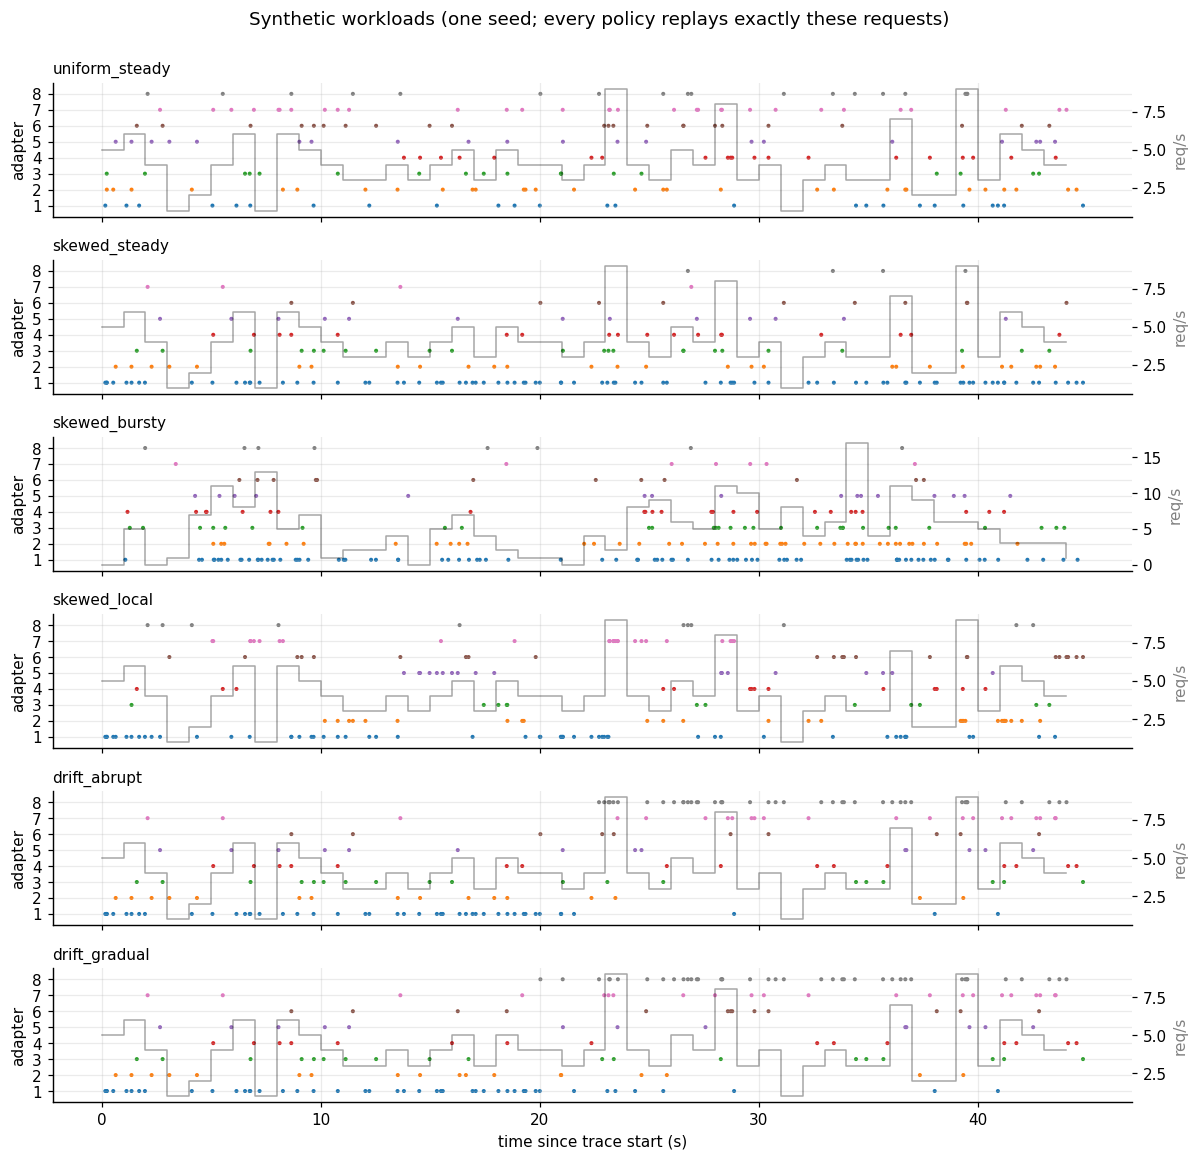

,requests,mean_rate,peak_req_per_s,top_adapter_share,adapters_seen
scenario,,,,,
uniform_steady,185,4.11,9,0.17,8
skewed_steady,185,4.11,9,0.46,8
skewed_bursty,232,5.16,17,0.38,8
skewed_local,185,4.11,9,0.30,8
drift_abrupt,185,4.11,9,0.24,8
drift_gradual,185,4.11,9,0.24,8


In [6]:
def plot_traces(traces, title, name):
    names = list(traces)
    fig, axes = plt.subplots(len(names), 1, figsize=(11, 1.75 * len(names)), sharex=True, squeeze=False)
    for ax, scen in zip(axes[:, 0], names):
        df = traces[scen]
        ax.scatter(df.arrival_s, df.adapter_id, s=7, c=df.adapter_id, cmap='tab10', vmin=1, vmax=10, linewidths=0)
        ax.set_yticks(ADAPTER_IDS)
        ax.set_ylim(0.3, CONFIG['n_adapters'] + 0.7)
        ax.set_ylabel('adapter')
        ax.set_title(scen, loc='left', fontsize=10)
        per_s = np.histogram(df.arrival_s, bins=np.arange(0, math.ceil(CONFIG['duration_s']) + 1))[0]
        ax2 = ax.twinx()
        ax2.step(np.arange(len(per_s)), per_s, where='post', color='black', alpha=0.35, lw=1)
        ax2.set_ylabel('req/s', color='gray')
        ax2.grid(False)
    axes[-1, 0].set_xlabel('time since trace start (s)')
    fig.suptitle(title, y=1.0)
    fig.tight_layout()
    savefig(fig, name)


def describe_traces(traces):
    rows = []
    for scen, df in traces.items():
        counts = df.adapter_id.value_counts(normalize=True)
        rows.append({'scenario': scen, 'requests': len(df),
                     'mean_rate': round(len(df) / CONFIG['duration_s'], 2),
                     'peak_req_per_s': int(np.histogram(df.arrival_s, bins=np.arange(0, CONFIG['duration_s'] + 1))[0].max()),
                     'top_adapter_share': round(counts.iloc[0], 2),
                     'adapters_seen': df.adapter_id.nunique()})
    return pd.DataFrame(rows).set_index('scenario')


if TRACES:
    plot_traces(TRACES, 'Synthetic workloads (one seed; every policy replays exactly these requests)', 'figW1_synthetic_traces')
    display(describe_traces(TRACES))

### 2.3 Real-trace check: Azure Functions 2021
Synthetic traces let us vary one factor at a time. A real trace checks that the conclusions survive a **realistic mix**.
No public trace contains LoRA adapter IDs, so we follow the related work (dLoRA, Predictive-LoRA):
**treat each serverless function as an adapter.** This is an assumption to state on a slide. A function's invocation
pattern stands in for an adapter's demand; it is not evidence of it.

We use the **2021 Azure Functions invocation trace** (Zhang et al., SOSP '21; CC-BY). It has per-invocation timestamps
over two weeks (1.98 M invocations, 424 functions), so real burstiness within each minute is preserved. The 2019 trace
only has per-minute counts.

How we turn it into an 8-adapter trace:
1. Download (18 MB `.rar`) once, extract with `unrar`, and keep only `(start time, function)`, where start = end − duration.
2. **Pick a window** of `azure_window_s` = 180 s. Auto-selection considers every 3-minute window, keeps those where
   the 8 busiest functions have enough requests and each appears at least 3 times, then picks the window with the
   **median** top-function share. That makes it a typical window, not the most extreme one.
3. Map the window's 8 busiest functions to adapters 1–8, in order of popularity. Drop the other functions and report what share of requests they were.
4. **Compress time** so the window fills `duration_s`, then **thin uniformly at random** to `mean_rate`.
   This keeps the relative burst and popularity structure, but the absolute rate is our choice. That is also an assumption to state.

If the download fails (no network, for example), the scenario is skipped and everything else still runs.

1,980,951 invocations, 424 functions; 4,263 candidate windows
{
  "window_start_s": 9960.0,
  "window_start_day": 0.115,
  "window_s": 180.0,
  "time_compression": 4.0,
  "requests_in_window_all_functions": 932,
  "share_of_window_from_top_k": 0.992,
  "thinning_keep_fraction": 0.195,
  "requests_after_thinning": 190,
  "function_ids_for_adapters_1_to_k": [
    155,
    0,
    2,
    1,
    102,
    73,
    5,
    3
  ]
}
saved figure: results/m2_20261102T221446Z/figures/figW2_azure_trace.png


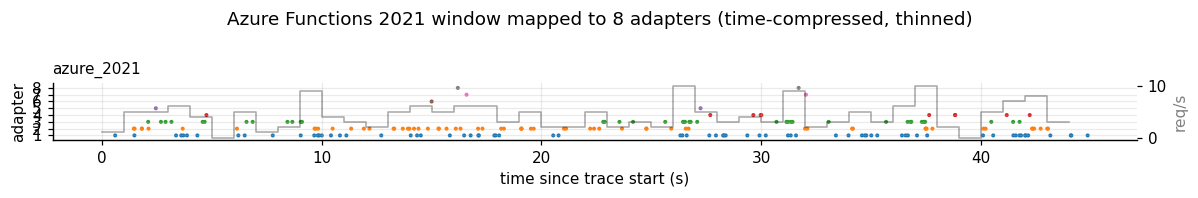

Scenarios for this run: ['uniform_steady', 'skewed_steady', 'skewed_bursty', 'skewed_local', 'drift_abrupt', 'drift_gradual', 'azure_2021']


In [7]:
AZURE_DIR = LAB / 'azure'
AZURE_DIR.mkdir(exist_ok=True)
AZURE_COMPACT = AZURE_DIR / 'azure_functions_2021_compact.csv.gz'


def ensure_unrar():
    """The archive is RAR v5; only `unrar` reliably extracts it. Colab can install it with apt."""
    if not shutil.which('unrar') and shutil.which('apt-get'):
        subprocess.run(['apt-get', 'install', '-y', '-qq', 'unrar'], capture_output=True)
    return shutil.which('unrar')


def load_azure_functions_2021():
    """Return a compact DataFrame (start_s, function) for all 1.98 M invocations, cached after the first call."""
    if AZURE_COMPACT.exists():
        return pd.read_csv(AZURE_COMPACT)
    rar = AZURE_DIR / 'AzureFunctionsInvocationTraceForTwoWeeksJan2021.rar'
    txt = AZURE_DIR / 'AzureFunctionsInvocationTraceForTwoWeeksJan2021.txt'
    if not txt.exists():
        if not rar.exists() or rar.stat().st_size < 1_000_000:
            import urllib.request
            print('Downloading the Azure Functions 2021 trace (~18 MB)...')
            urllib.request.urlretrieve(CONFIG['azure_url'], rar)
        if rar.read_bytes()[:4] != b'Rar!':
            raise RuntimeError(f'{rar} is not a RAR archive; the download probably failed.')
        tool = ensure_unrar()
        if not tool:
            raise RuntimeError(f'`unrar` is unavailable. Extract the archive elsewhere and upload the .txt to {AZURE_DIR}')
        subprocess.run([tool, 'x', '-o+', str(rar), str(AZURE_DIR) + os.sep], check=True, capture_output=True)
    raw = pd.read_csv(txt, dtype={'app': 'category', 'func': 'category'})
    compact = pd.DataFrame({
        'start_s': (raw['end_timestamp'] - raw['duration']).round(4),
        'function': raw.groupby(['app', 'func'], observed=True).ngroup().astype('int32'),
    })
    compact.to_csv(AZURE_COMPACT, index=False)
    del raw
    gc.collect()
    return compact


def azure_windows(compact, k, window_s, min_requests):
    """Score every whole-minute-aligned window. Returns a DataFrame of candidate windows."""
    minute = np.clip((compact['start_s'].to_numpy() // 60).astype(int), 0, None)
    func = compact['function'].to_numpy()
    counts = np.zeros((minute.max() + 1, func.max() + 1), dtype=np.int32)
    np.add.at(counts, (minute, func), 1)
    w = int(window_s // 60)
    csum = np.cumsum(counts, axis=0, dtype=np.int64)
    win = csum[w - 1:] - np.vstack([np.zeros((1, counts.shape[1]), dtype=np.int64), csum[:-w]])
    topk = -np.sort(-win, axis=1)[:, :k]
    total = topk.sum(axis=1)
    frame = pd.DataFrame({'start_s': np.arange(len(win)) * 60.0, 'topk_requests': total,
                          'kth_count': topk[:, -1], 'top1_share': topk[:, 0] / np.maximum(total, 1)})
    return frame[(frame.topk_requests >= min_requests) & (frame.kth_count >= 3)].reset_index(drop=True)


def azure_to_trace(compact, start_s, window_s, k, duration_s, mean_rate, seed, name='azure_2021'):
    """Map the window's k busiest functions to adapters 1..k, compress time, thin to mean_rate."""
    window = compact[(compact.start_s >= start_s) & (compact.start_s < start_s + window_s)]
    top = window['function'].value_counts().head(k)
    mapping = {f: i + 1 for i, f in enumerate(top.index)}
    sub = window[window['function'].isin(mapping)].sort_values('start_s')
    keep_p = min(1.0, mean_rate * duration_s / max(len(sub), 1))
    keep = np.random.default_rng(seed).random(len(sub)) < keep_p
    sub = sub[keep]
    trace = pd.DataFrame({'arrival_s': ((sub.start_s - start_s) * duration_s / window_s).to_numpy(),
                          'adapter_id': sub['function'].map(mapping).to_numpy().astype(int),
                          'drift_weight': 0.0, 'in_burst': False, 'locality_repeat': False, 'scenario': name})
    info = {'window_start_s': float(start_s), 'window_start_day': round(start_s / 86400, 3),
            'window_s': window_s, 'time_compression': round(window_s / duration_s, 2),
            'requests_in_window_all_functions': int(len(window)),
            'share_of_window_from_top_k': round(float(top.sum()) / max(len(window), 1), 3),
            'thinning_keep_fraction': round(keep_p, 3), 'requests_after_thinning': int(len(trace)),
            'function_ids_for_adapters_1_to_k': [int(f) for f in mapping]}
    return trace, info


AZURE = None
if 'azure_2021' in CONFIG['scenarios']:
    try:
        AZURE = load_azure_functions_2021()
        min_req = CONFIG['mean_rate'] * CONFIG['duration_s']
        AZURE_CANDIDATES = azure_windows(AZURE, CONFIG['n_adapters'], CONFIG['azure_window_s'], min_req)
        if CONFIG['azure_window_start_s'] is not None:
            AZURE_START = float(CONFIG['azure_window_start_s'])
        elif len(AZURE_CANDIDATES):
            ranked = AZURE_CANDIDATES.sort_values('top1_share').reset_index(drop=True)
            AZURE_START = float(ranked.loc[len(ranked) // 2, 'start_s'])
        else:
            raise RuntimeError('No window has enough requests; lower mean_rate or raise azure_window_s.')

        def azure_trace_for_seed(seed):
            """Seed CONFIG['seed'] uses the selected window. Other seeds use other candidate windows (for simulator spread)."""
            if seed == CONFIG['seed']:
                start = AZURE_START
            else:
                start = float(AZURE_CANDIDATES.sample(1, random_state=seed)['start_s'].iloc[0])
            return azure_to_trace(AZURE, start, CONFIG['azure_window_s'], CONFIG['n_adapters'],
                                  CONFIG['duration_s'], CONFIG['mean_rate'], seed)[0]

        TRACES['azure_2021'], AZURE_INFO = azure_to_trace(
            AZURE, AZURE_START, CONFIG['azure_window_s'], CONFIG['n_adapters'],
            CONFIG['duration_s'], CONFIG['mean_rate'], CONFIG['seed'])
        (RUN_DIR / 'azure_window.json').write_text(json.dumps(AZURE_INFO, indent=2))
        print(f'{len(AZURE):,} invocations, {AZURE.function.nunique()} functions; '
              f'{len(AZURE_CANDIDATES):,} candidate windows')
        print(json.dumps(AZURE_INFO, indent=2))
        plot_traces({'azure_2021': TRACES['azure_2021']},
                    'Azure Functions 2021 window mapped to 8 adapters (time-compressed, thinned)', 'figW2_azure_trace')
    except Exception as exc:
        print('Azure trace unavailable, so the scenario is skipped:', repr(exc))
        CONFIG['scenarios'] = [s for s in CONFIG['scenarios'] if s != 'azure_2021']

SCENARIOS = [s for s in CONFIG['scenarios'] if s in TRACES]
(RUN_DIR / 'traces').mkdir(exist_ok=True)
for scen in SCENARIOS:
    TRACES[scen].to_csv(RUN_DIR / 'traces' / f'{scen}.csv', index=False)
print('Scenarios for this run:', SCENARIOS)

### 2.4 Which trace for which seed
Seed `CONFIG['seed']` gives the traces replayed on the GPU. The CPU simulator in Part 4 also uses other seeds,
which produce new synthetic draws and, for Azure, other candidate windows, to show how much results vary across workload realisations.

In [8]:
def trace_for(scenario, seed):
    if scenario == 'azure_2021':
        return azure_trace_for_seed(seed)
    return synthetic_trace(scenario, seed)

---
# Part 3: Caching and prefetch policies
All three policies share one interface. The replay loop, both the CPU simulator and the GPU harness, calls:
* `observe(adapter, t)` when a request **arrives**. This is the only information a predictor gets, so there is no look-ahead.
* `close_tick()` every `tick_s` = 0.25 s, which updates the EWMA.
* `decide(t, view)` right after each tick. `view` holds the resident adapters in LRU order (oldest first), the adapters
  with queued or running requests (`busy`), and the in-flight count. It returns a list of decisions. Each decision is logged,
  **including the rejected ones and the reason they were rejected**.

**EWMA rate estimate** (proposal §4.3, following the NIST/SEMATECH exponential-smoothing handbook): each tick,

$$\hat\lambda_a \leftarrow \alpha\cdot\frac{\text{requests for } a \text{ in the last tick}}{\Delta t} + (1-\alpha)\,\hat\lambda_a$$

so $\hat\lambda_a$ is in **requests per second**, and the time constant is $\Delta t/\alpha$ = 2.5 s. Milestone 1's preview
updated per request. Updating per tick handles idle gaps and bursts more naturally, and it makes the admission thresholds interpretable.

**EWMA (naive):** keep the top-*k* adapters by $\hat\lambda$ resident, where *k* = number of slots. Any non-resident top-*k* adapter is
prefetched, and vLLM's LRU picks the victim. This version is deliberately cost-blind.

**EWMA+admission (cost-aware, proposal §4.4):** the same candidates, but a prefetch must pass all four rules.
Each rule targets one failure mode we expect:

| Rule | Condition to prefetch candidate *c* | Failure mode it prevents |
|---|---|---|
| **R1 victim** | Some resident adapter *v* is **idle** (no queued or running request) and not itself in the top-*k*. Older residents that must be protected are *touched* first, so LRU evicts exactly *v*. | Evicting an adapter the current batch needs, which forces an immediate demand reload. |
| **R2 benefit** | $(\hat\lambda_c-\hat\lambda_v)\cdot H \ge 0.5$ with H = 2 s: expect at least half a request more for *c* than for *v* in the next 2 s. The threshold comes from the trade-off curve in Part 4.4. | Churn when popularity is flat or noisy. With equal-size adapters the copy cost cancels, so benefit reduces to this rate gap. |
| **R3 busy** | ≤ 4 requests in flight. | Milestone 1's hidden assumption: a prefetch is only free when there is idle time to hide it. Under load it delays the whole batch. |
| **R4 budget** | ≤ 2 speculative loads per second (token bucket). | Bursts of wasted transfers during unstable phases, such as drift. |

In [9]:
class EWMARates:
    """Per-adapter request-rate estimate in requests/second, updated once per tick.

    rate ← alpha · (requests in the last tick / tick_s) + (1 − alpha) · rate
    Only requests that have already arrived are counted."""

    def __init__(self, n_adapters, alpha, tick_s):
        self.alpha, self.tick_s = alpha, tick_s
        self.rate = np.zeros(n_adapters + 1)      # index = adapter id; index 0 unused
        self.pending = np.zeros(n_adapters + 1)

    def observe(self, adapter_id):
        self.pending[adapter_id] += 1

    def close_tick(self):
        self.rate = self.alpha * self.pending / self.tick_s + (1 - self.alpha) * self.rate
        self.pending[:] = 0

    def top(self, k, min_rate):
        """The k highest-rate adapters (ties → lower id), excluding ones below min_rate."""
        order = sorted(range(1, len(self.rate)), key=lambda a: (-self.rate[a], a))
        return [a for a in order[:k] if self.rate[a] >= min_rate]


class LRUPolicy:
    """vLLM's default: adapters are activated only when a scheduled request needs them. Never prefetches.
    It still maintains the EWMA, so logs can show what a predictor *would* have believed."""
    name = 'LRU'

    def __init__(self, n_slots, cfg=None):
        self.n_slots, self.cfg = n_slots, cfg or CONFIG
        self.reset()

    def reset(self):
        self.rates = EWMARates(self.cfg['n_adapters'], self.cfg['ewma_alpha'], self.cfg['tick_s'])

    def observe(self, adapter_id, t):
        self.rates.observe(int(adapter_id))

    def close_tick(self):
        self.rates.close_tick()

    def decide(self, t, view):
        return []

    def _decision(self, t, c, victim=None):
        return {'t': t, 'policy': self.name, 'candidate': c, 'victim': victim, 'action': 'skip', 'reason': '',
                'touches': [], 'rate_candidate': float(self.rates.rate[c]),
                'rate_victim': float(self.rates.rate[victim]) if victim else 0.0}


class EWMAPolicy(LRUPolicy):
    """Naive predictor: prefetch every top-k adapter (k = slots) that is not resident. LRU picks the victim."""
    name = 'EWMA'

    def decide(self, t, view):
        resident, out = list(view['resident_lru']), []
        for c in self.rates.top(self.n_slots, self.cfg['min_rate']):
            if c in resident:
                continue
            victim = resident[0] if len(resident) >= self.n_slots else None
            d = self._decision(t, c, victim)
            d['action'], d['reason'] = 'prefetch', 'top_k'
            out.append(d)
            if victim is not None:
                resident.remove(victim)
            resident.append(c)
        return out


class EWMAAdmissionPolicy(LRUPolicy):
    """EWMA prediction + cost-aware admission (rules R1–R4 in the table above)."""
    name = 'EWMA+admission'

    def reset(self):
        super().reset()
        self.tokens, self.last_t = 1.0, 0.0

    def decide(self, t, view):
        cfg = self.cfg
        self.tokens = min(float(self.n_slots), self.tokens + (t - self.last_t) * cfg['admit_max_prefetch_per_s'])
        self.last_t = t
        resident = list(view['resident_lru'])
        targets = self.rates.top(self.n_slots, cfg['min_rate'])
        out = []
        for c in targets:
            if c in resident:
                continue
            d = self._decision(t, c)
            out.append(d)
            if view['inflight'] > cfg['admit_max_inflight']:
                d['reason'] = 'R3_busy'
                continue
            if self.tokens < 1.0:
                d['reason'] = 'R4_budget'
                continue
            if len(resident) >= self.n_slots:
                eligible = [v for v in resident if v not in view['busy'] and v not in targets]
                if not eligible:
                    d['reason'] = 'R1_victim_in_use'
                    continue
                victim = eligible[0]
                d['victim'], d['rate_victim'] = victim, float(self.rates.rate[victim])
                if (d['rate_candidate'] - d['rate_victim']) * cfg['admit_horizon_s'] < cfg['admit_min_net_hits']:
                    d['reason'] = 'R2_low_benefit'
                    continue
                d['touches'] = resident[:resident.index(victim)]   # protect older, still-wanted adapters
                for a in d['touches']:
                    resident.remove(a)
                    resident.append(a)
                resident.remove(victim)
            d['action'], d['reason'] = 'prefetch', 'admitted'
            resident.append(c)
            self.tokens -= 1.0
        return out


POLICIES = {cls.name: cls for cls in (LRUPolicy, EWMAPolicy, EWMAAdmissionPolicy)}
print('Policies:', list(POLICIES))

Policies: ['LRU', 'EWMA', 'EWMA+admission']


### 3.1 Unit checks
These are small, hand-computed cases that a reviewer can verify by reading. If any assertion fails, the policies are wrong and no later result should be trusted.

In [10]:
_cfg = dict(CONFIG, n_adapters=4, ewma_alpha=0.5, tick_s=0.25, min_rate=0.05,
            admit_horizon_s=2.0, admit_min_net_hits=0.5, admit_max_inflight=4, admit_max_prefetch_per_s=2.0)

r = EWMARates(4, alpha=0.5, tick_s=0.25)
for _ in range(4):
    r.observe(3)
r.close_tick()
assert r.rate[3] == 0.5 * 4 / 0.25 == 8.0 and r.rate[1] == 0          # 4 requests in 0.25 s = 16 req/s, half-weighted
r.close_tick()
assert r.rate[3] == 4.0                                                # decays by (1 - alpha) with no new requests

p = EWMAPolicy(2, _cfg)
for _ in range(3):
    p.observe(3, 0.0)
p.close_tick()
d = p.decide(0.25, {'resident_lru': [1, 2], 'busy': set(), 'inflight': 0})
assert [(x['candidate'], x['victim'], x['action']) for x in d] == [(3, 1, 'prefetch')]   # LRU victim = oldest = 1

q = EWMAAdmissionPolicy(2, _cfg)
for _ in range(3):
    q.observe(3, 0.0)
q.close_tick()
d = q.decide(0.25, {'resident_lru': [1, 2], 'busy': {1, 2}, 'inflight': 2})
assert d[0]['action'] == 'skip' and d[0]['reason'] == 'R1_victim_in_use'                 # both residents are in use
d = q.decide(0.5, {'resident_lru': [1, 2], 'busy': {1}, 'inflight': 1})
assert d[0]['action'] == 'prefetch' and d[0]['victim'] == 2 and d[0]['touches'] == [1]   # touch 1 so LRU evicts 2
d = q.decide(0.5, {'resident_lru': [1, 2], 'busy': set(), 'inflight': 9})
assert d[0]['reason'] == 'R3_busy'
q2 = EWMAAdmissionPolicy(2, _cfg)
q2.observe(3, 0.0)
q2.close_tick()        # rate[3] = 0.5 * 1 / 0.25 = 2 req/s → (2 − 0) × 2 s = 4 ≥ 0.5, admitted
assert q2.decide(0.25, {'resident_lru': [1, 2], 'busy': set(), 'inflight': 0})[0]['action'] == 'prefetch'
q2.rates.rate[1], q2.rates.rate[2] = 2.1, 1.8   # top-2 = [1, 3]; only 2 can be the victim
q2.tokens = 2                                    # (2.0 − 1.8) × 2 s = 0.4 < 0.5 → rejected by R2
assert q2.decide(0.5, {'resident_lru': [1, 2], 'busy': set(), 'inflight': 0})[0]['reason'] == 'R2_low_benefit'
print('All policy unit checks passed.')

All policy unit checks passed.


---
# Part 4: CPU simulator (pre-GPU expectations)
The proposal's fallback (§4.6) is a CPU simulator. Here we use it **alongside** the GPU, for three reasons:
1. GPU time is scarce. The simulator runs 20 seeds per scenario in seconds, which gives **uncertainty estimates** the single GPU replay cannot.
2. It lets us **sweep** skew and locality densely, to map *where* prediction helps.
3. Part 7 compares simulator and GPU hit rates on identical traces. Agreement tells us the simulator can be trusted for larger sweeps later.

**What it models:** a resident set of *S* adapters with LRU eviction, a demand load at every arrival that misses, the
same policy objects and tick schedule, and prefetches with vLLM's LRU victim choice.
**What it does not model:** latency, batching, the per-batch `max_loras` limit, or queueing. A request counts as in flight
for a fixed `sim_service_s` = 0.4 s. Its outputs are **counts only**: hit rate, loads, and useful or wasted prefetches.

In [11]:
def simulate(trace, policy, cfg=None):
    """Count-only replay of `trace` with `policy.n_slots` GPU slots.
    Returns (summary dict, per-request hit-at-arrival array)."""
    cfg = cfg or CONFIG
    n_slots = policy.n_slots
    policy.reset()
    lru = OrderedDict()                 # resident adapters, oldest first, like vLLM's GPU slot cache
    prefetched_unused = set()           # resident because of a prefetch, not yet used by a request
    evicted_by_prefetch = {}            # adapter -> time a prefetch evicted it (cleared by a demand eviction)
    recent = deque()                    # (arrival time, adapter) for requests still "in flight"
    stats, hits = Counter(), []
    tick, next_tick = cfg['tick_s'], cfg['tick_s']

    def load(adapter, source, now):
        if len(lru) >= n_slots:
            victim, _ = lru.popitem(last=False)
            stats['evictions'] += 1
            if victim in prefetched_unused:
                prefetched_unused.discard(victim)
                stats['wasted_prefetches'] += 1
            if source == 'prefetch':
                evicted_by_prefetch[victim] = now
            else:
                evicted_by_prefetch.pop(victim, None)
        lru[adapter] = None

    for t, a in zip(trace['arrival_s'].to_numpy(float), trace['adapter_id'].to_numpy(int)):
        while next_tick <= t:                                  # ticks strictly before this arrival
            policy.close_tick()
            while recent and next_tick - recent[0][0] > cfg['sim_service_s']:
                recent.popleft()
            view = {'resident_lru': list(lru), 'busy': {x for _, x in recent}, 'inflight': len(recent)}
            for d in policy.decide(next_tick, view):
                if d['action'] != 'prefetch':
                    stats['skip_' + d['reason']] += 1
                    continue
                for x in d['touches']:
                    lru.move_to_end(x)
                if d['candidate'] not in lru:
                    load(d['candidate'], 'prefetch', next_tick)
                    prefetched_unused.add(d['candidate'])
                    stats['prefetches'] += 1
            next_tick += tick
        policy.observe(a, t)
        recent.append((t, a))
        hit = a in lru
        if hit:
            lru.move_to_end(a)
            if a in prefetched_unused:
                prefetched_unused.discard(a)
                stats['useful_prefetches'] += 1
        else:
            stats['demand_loads'] += 1
            if t - evicted_by_prefetch.pop(a, -math.inf) <= cfg['admit_horizon_s']:
                stats['prefetch_induced_loads'] += 1      # needed again soon after a prefetch evicted it
            load(a, 'demand', t)
        hits.append(hit)
    stats['wasted_prefetches'] += len(prefetched_unused)        # still unused when the trace ends
    n = len(hits)
    summary = {'requests': n, 'hit_rate': float(np.mean(hits)) if n else float('nan')}
    for key in ('demand_loads', 'prefetches', 'useful_prefetches', 'wasted_prefetches', 'prefetch_induced_loads', 'evictions'):
        summary[key] = stats.get(key, 0)
    summary.update({k: v for k, v in stats.items() if k.startswith('skip_')})
    return summary, np.asarray(hits)


def per100(df, cols):
    out = df.copy()
    for c in cols:
        out[c + '_per100'] = 100 * out[c] / out['requests']
    return out


t0 = time.perf_counter()
sim_rows = []
for scen in SCENARIOS:
    for seed in range(CONFIG['seed'], CONFIG['seed'] + CONFIG['sim_seeds']):
        tr = trace_for(scen, seed)
        for slots in CONFIG['slot_configs']:
            for pname, cls in POLICIES.items():
                s, _ = simulate(tr, cls(slots))
                sim_rows.append({'scenario': scen, 'seed': seed, 'slots': slots, 'policy': pname, **s})
SIM = per100(pd.DataFrame(sim_rows).fillna(0),
             ['demand_loads', 'prefetches', 'useful_prefetches', 'wasted_prefetches', 'prefetch_induced_loads'])
SIM.to_csv(RUN_DIR / 'sim_results.csv', index=False)
print(f'{len(SIM)} simulations in {time.perf_counter() - t0:.1f} s')

sim_table = (SIM.groupby(['slots', 'scenario', 'policy'], sort=False)
             .agg(hit_rate=('hit_rate', 'mean'), hit_rate_sd=('hit_rate', 'std'),
                  demand_loads_per100=('demand_loads_per100', 'mean'),
                  prefetches_per100=('prefetches_per100', 'mean'),
                  wasted_per100=('wasted_prefetches_per100', 'mean'),
                  induced_loads_per100=('prefetch_induced_loads_per100', 'mean'))
             .round(3))
display(sim_table)

840 simulations in 2.7 s


hit_rate  hit_rate_sd  demand_loads_per100  prefetches_per100  wasted_per100  induced_loads_per100
slots scenario       policy                                                                                                            
2     uniform_steady LRU                0.245        0.030               75.482              0.000          0.000                 0.000
                     EWMA               0.251        0.025               74.895             52.792         43.177                22.805
                     EWMA+admission     0.252        0.030               74.812              6.984          5.027                 4.617
4     uniform_steady LRU                0.497        0.035               50.330              0.000          0.000                 0.000
                     EWMA               0.496        0.038               50.415             53.233         36.697                17.905
                     EWMA+admission     0.496        0.035               50.377              6.263          3.267                 4.036
2     skewed_steady  LRU                0.435        0.042               56.540              0.000          0.000                 0.000
                     EWMA               0.512        0.044               48.753             37.378         21.916                13.612
                     EWMA+admission     0.466        0.044               53.352              8.790          4.194                 3.716
4     skewed_steady  LRU                0.705        0.040               29.452              0.000          0.000                 0.000
                     EWMA               0.725        0.032               27.467             21.555         11.447                 6.196
                     EWMA+admission     0.722        0.034               27.758              4.068          1.182                 1.449
2     skewed_bursty  LRU                0.424        0.043               57.611              0.000          0.000                 0.000
                     EWMA               0.475        0.039               52.452             33.109         20.358                13.600
                     EWMA+admission     0.438        0.045               56.200              5.553          2.939                 2.160
4     skewed_bursty  LRU                0.703        0.042               29.677              0.000          0.000                 0.000
                     EWMA               0.716        0.041               28.399             21.964         12.203                 6.565
                     EWMA+admission     0.718        0.039               28.167              4.013          1.276                 1.393
2     skewed_local   LRU                0.603        0.034               39.714              0.000          0.000                 0.000
                     EWMA               0.544        0.046               45.624             37.757         28.507                16.158
                     EWMA+admission     0.585        0.039               41.459              8.758          6.489                 4.617
4     skewed_local   LRU                0.775        0.030               22.509              0.000          0.000                 0.000
                     EWMA               0.771        0.035               22.871             21.701         14.621                 5.139
                     EWMA+admission     0.779        0.028               22.138              4.355          2.306                 1.569
2     drift_abrupt   LRU                0.434        0.060               56.591              0.000          0.000                 0.000
                     EWMA               0.498        0.052               50.224             38.732         23.497                13.706
                     EWMA+admission     0.465        0.060               53.494              9.030          4.253                 4.099
4     drift_abrupt   LRU                0.696        0.049               30.435              

### 4.1 Simulator: hit rate by scenario
Bars are mean hit-at-arrival over seeds, with error bars showing a 95% confidence interval of the mean.
The comparison to read is each predictor **against LRU in the same scenario**. Wasted prefetches are in the table above.

saved figure: results/m2_20261102T221446Z/figures/figS1_sim_hit_rates.png


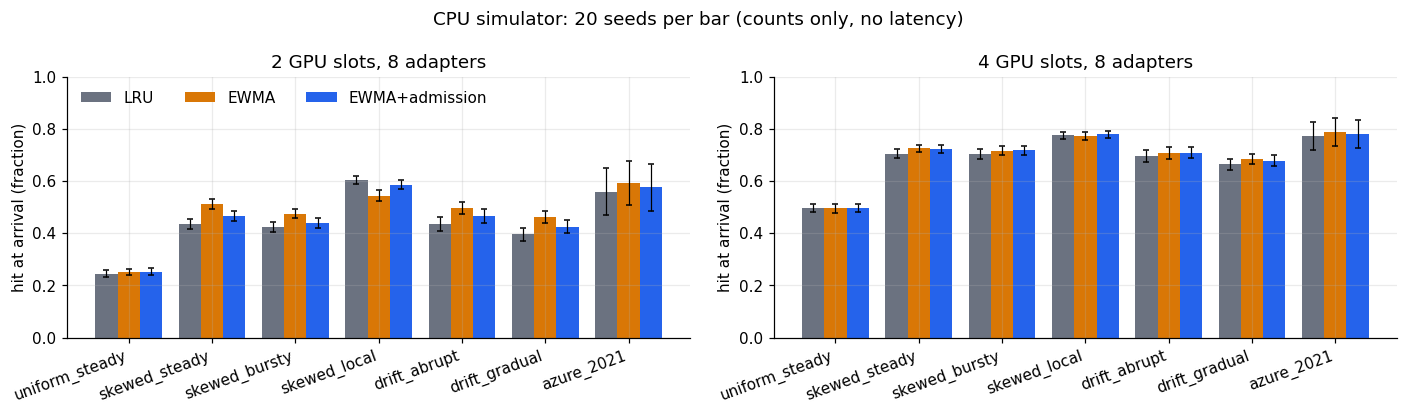

In [12]:
def grouped_bars(ax, df, value, err=None, ylabel='', scenarios=None):
    scenarios = scenarios or [s for s in SCENARIOS if s in set(df.scenario)]
    width = 0.8 / len(POLICY_ORDER)
    x = np.arange(len(scenarios))
    for i, pol in enumerate(POLICY_ORDER):
        sub = df[df.policy == pol].set_index('scenario').reindex(scenarios)
        ax.bar(x + (i - 1) * width, sub[value], width, color=POLICY_COLORS[pol], label=pol,
               yerr=None if err is None else sub[err], capsize=2, error_kw={'lw': 0.8})
    ax.set_xticks(x, scenarios, rotation=20, ha='right')
    ax.set_ylabel(ylabel)


agg = (SIM.groupby(['slots', 'scenario', 'policy'])
       .agg(hit=('hit_rate', 'mean'), sd=('hit_rate', 'std'), n=('hit_rate', 'size')).reset_index())
agg['ci'] = 1.96 * agg['sd'] / np.sqrt(agg['n'])
fig, axes = plt.subplots(1, len(CONFIG['slot_configs']), figsize=(6.5 * len(CONFIG['slot_configs']), 3.8), squeeze=False)
for ax, slots in zip(axes[0], CONFIG['slot_configs']):
    grouped_bars(ax, agg[agg.slots == slots], 'hit', 'ci', 'hit at arrival (fraction)')
    ax.set_title(f'{slots} GPU slots, {CONFIG["n_adapters"]} adapters')
    ax.set_ylim(0, 1)
axes[0, 0].legend(frameon=False, ncol=3, loc='upper left')
fig.suptitle(f'CPU simulator: {CONFIG["sim_seeds"]} seeds per bar (counts only, no latency)')
fig.tight_layout()
savefig(fig, 'figS1_sim_hit_rates')

### 4.2 Where does prediction help? A skew × locality sweep
This shows the hit-rate gain over LRU, in percentage points, and the wasted prefetches per 100 requests, across a grid of popularity skew (Zipf *s*)
and temporal locality (`p_repeat`), with steady arrivals and the **smallest** slot count (most pressure).
It is the simulator's first answer to research question 1. Expect the gains in the high-skew, low-locality corner
(LRU already exploits locality well) and losses or waste near uniform popularity.

saved figure: results/m2_20261102T221446Z/figures/figS2_sweep_skew_locality.png


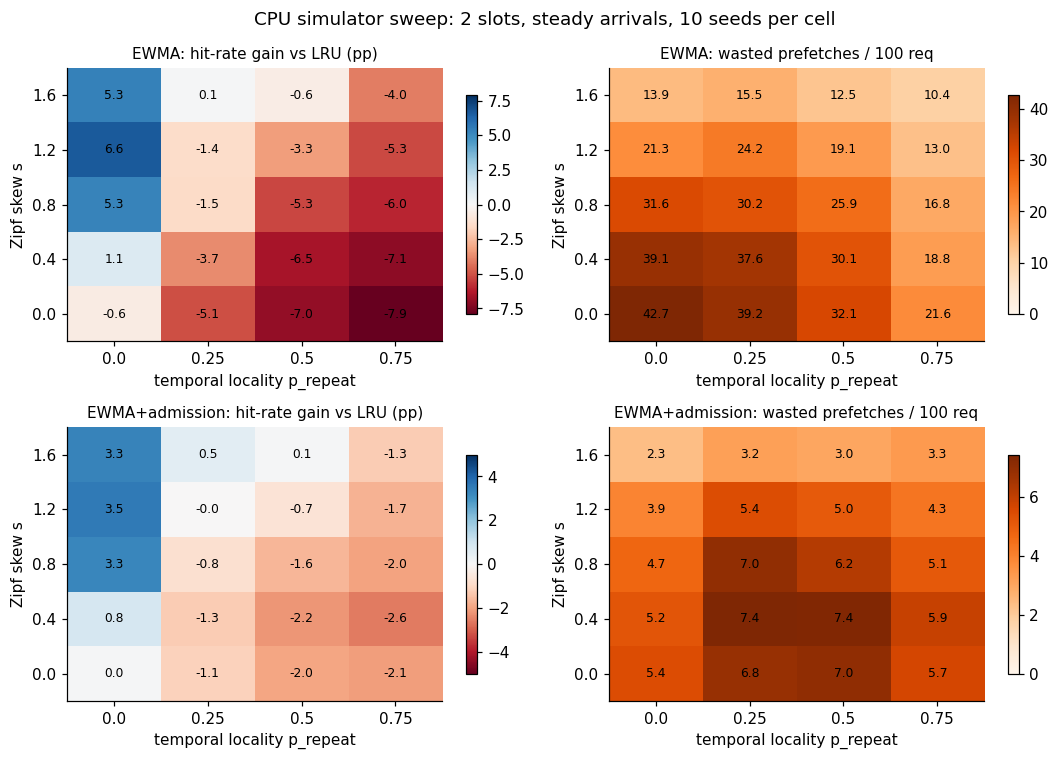

In [13]:
SKEWS = [0.0, 0.4, 0.8, 1.2, 1.6]
LOCALITIES = [0.0, 0.25, 0.5, 0.75]
SWEEP_SEEDS = range(100, 100 + max(5, CONFIG['sim_seeds'] // 2))
slots = min(CONFIG['slot_configs'])
sweep_rows = []
for s in SKEWS:
    for pr in LOCALITIES:
        for seed in SWEEP_SEEDS:
            tr = make_synthetic_trace('sweep', seed, zipf_s=s,
                                      locality=dict(p_repeat=pr, window=3) if pr else None)
            for pname, cls in POLICIES.items():
                res, _ = simulate(tr, cls(slots))
                sweep_rows.append({'zipf_s': s, 'p_repeat': pr, 'seed': seed, 'policy': pname, **res})
SWEEP = pd.DataFrame(sweep_rows)
SWEEP.to_csv(RUN_DIR / 'sim_sweep_skew_locality.csv', index=False)

base = SWEEP[SWEEP.policy == 'LRU'].set_index(['zipf_s', 'p_repeat', 'seed'])['hit_rate']
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for row, pol in enumerate(['EWMA', 'EWMA+admission']):
    sub = SWEEP[SWEEP.policy == pol].set_index(['zipf_s', 'p_repeat', 'seed'])
    gain = (100 * (sub['hit_rate'] - base)).groupby(level=[0, 1]).mean().unstack()
    waste = (100 * sub['wasted_prefetches'] / sub['requests']).groupby(level=[0, 1]).mean().unstack()
    for col, (mat, title, cmap, vlim) in enumerate([
            (gain, 'hit-rate gain vs LRU (pp)', 'RdBu', max(5, np.nanmax(np.abs(gain.values)))),
            (waste, 'wasted prefetches / 100 req', 'Oranges', None)]):
        ax = axes[row, col]
        im = ax.imshow(mat.values, cmap=cmap, origin='lower', aspect='auto',
                       vmin=-vlim if vlim else 0, vmax=vlim if vlim else None)
        ax.set_xticks(range(len(LOCALITIES)), LOCALITIES)
        ax.set_yticks(range(len(SKEWS)), SKEWS)
        ax.set_xlabel('temporal locality p_repeat')
        ax.set_ylabel('Zipf skew s')
        ax.set_title(f'{pol}: {title}', fontsize=10)
        ax.grid(False)
        for (i, j), v in np.ndenumerate(mat.values):
            ax.text(j, i, f'{v:.1f}', ha='center', va='center', fontsize=8)
        fig.colorbar(im, ax=ax, shrink=0.8)
fig.suptitle(f'CPU simulator sweep: {slots} slots, steady arrivals, {len(SWEEP_SEEDS)} seeds per cell')
fig.tight_layout()
savefig(fig, 'figS2_sweep_skew_locality')

### 4.3 Sensitivity to the EWMA smoothing factor α
A small α remembers longer, which is stable but slow to notice drift. A large α reacts fast, but it is noisy and causes more wasted prefetches.
This sweep justifies the default (α = 0.1, a 2.5 s time constant) and shows the stability/agility trade-off from research question 2.

saved figure: results/m2_20261102T221446Z/figures/figS3_alpha_sensitivity.png


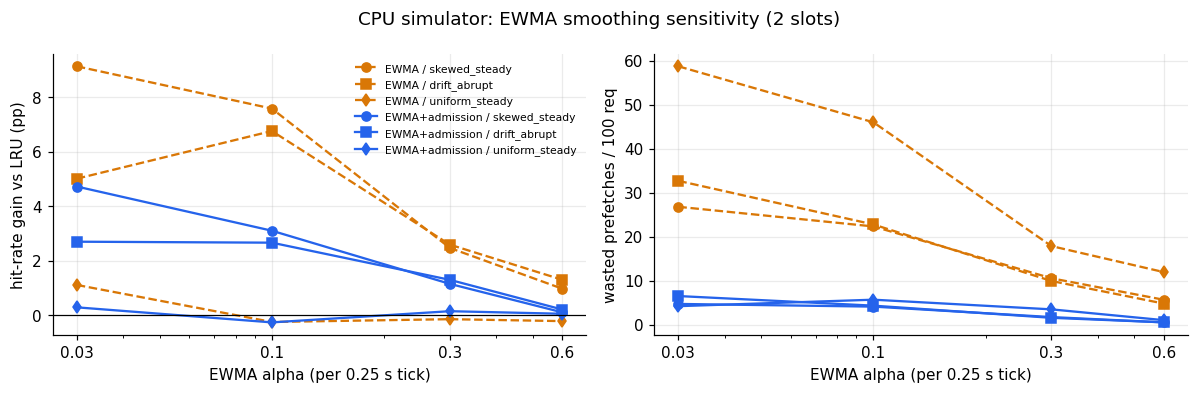

In [14]:
ALPHAS = [0.03, 0.1, 0.3, 0.6]
alpha_scenarios = [s for s in ['skewed_steady', 'drift_abrupt', 'uniform_steady'] if s in SCENARIO_SPECS]
alpha_rows = []
slots = min(CONFIG['slot_configs'])
for scen in alpha_scenarios:
    for seed in range(200, 200 + max(5, CONFIG['sim_seeds'] // 2)):
        tr = synthetic_trace(scen, seed)
        lru_hit = simulate(tr, LRUPolicy(slots))[0]['hit_rate']
        for alpha in ALPHAS:
            cfg = dict(CONFIG, ewma_alpha=alpha)
            for pname in ['EWMA', 'EWMA+admission']:
                res, _ = simulate(tr, POLICIES[pname](slots, cfg), cfg=cfg)
                alpha_rows.append({'scenario': scen, 'alpha': alpha, 'policy': pname, 'seed': seed,
                                   'gain_pp': 100 * (res['hit_rate'] - lru_hit),
                                   'wasted_per100': 100 * res['wasted_prefetches'] / res['requests']})
ALPHA_SWEEP = pd.DataFrame(alpha_rows)
ALPHA_SWEEP.to_csv(RUN_DIR / 'sim_sweep_alpha.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for pname, ls in [('EWMA', '--'), ('EWMA+admission', '-')]:
    for scen, marker in zip(alpha_scenarios, 'osd'):
        m = ALPHA_SWEEP[(ALPHA_SWEEP.policy == pname) & (ALPHA_SWEEP.scenario == scen)].groupby('alpha').mean(numeric_only=True)
        axes[0].plot(m.index, m.gain_pp, ls=ls, marker=marker, color=POLICY_COLORS[pname], label=f'{pname} / {scen}')
        axes[1].plot(m.index, m.wasted_per100, ls=ls, marker=marker, color=POLICY_COLORS[pname])
axes[0].axhline(0, color='black', lw=0.8)
axes[0].set_ylabel('hit-rate gain vs LRU (pp)')
axes[1].set_ylabel('wasted prefetches / 100 req')
for ax in axes:
    ax.set_xscale('log')
    ax.set_xticks(ALPHAS, ALPHAS)
    ax.set_xlabel('EWMA alpha (per 0.25 s tick)')
axes[0].legend(fontsize=7, frameon=False)
fig.suptitle(f'CPU simulator: EWMA smoothing sensitivity ({slots} slots)')
fig.tight_layout()
savefig(fig, 'figS3_alpha_sensitivity')

### 4.4 Cost-aware admission: how much waste for how much benefit? (research question 3)
Rule R2's threshold sets the trade-off. A low threshold admits more prefetches, gaining more hits and wasting more transfers. A high threshold does the opposite.
Each line is one scenario, and its points are thresholds from 0 to 2 expected extra requests. The ★ is naive EWMA (no admission at all).
**Good admission control moves points up and to the left of the ★**: most of the gain, little of the waste.
The default threshold (0.5) was chosen from this figure, before any GPU run.

saved figure: results/m2_20261102T221446Z/figures/figS4_admission_tradeoff.png


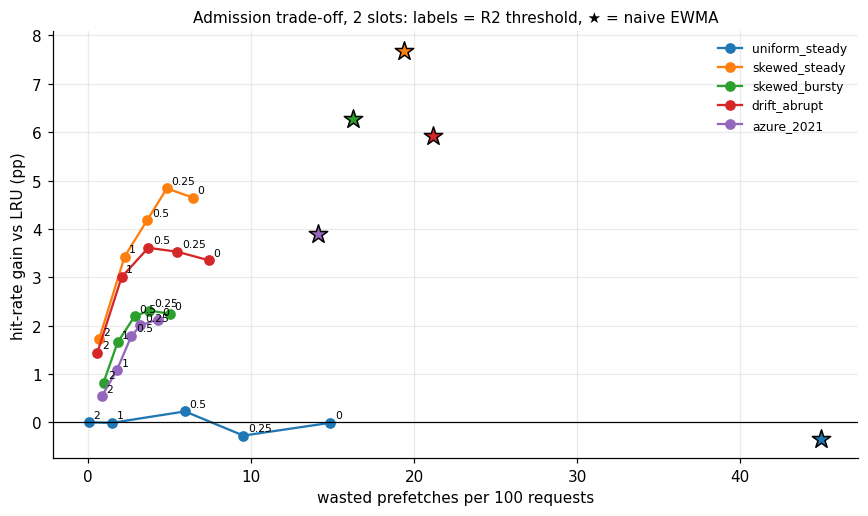

In [15]:
THRESHOLDS = [0.0, 0.25, 0.5, 1.0, 2.0]
tradeoff_scenarios = [s for s in ['uniform_steady', 'skewed_steady', 'skewed_bursty', 'drift_abrupt', 'azure_2021']
                      if s in SCENARIOS]
slots = min(CONFIG['slot_configs'])
rows = []
for scen in tradeoff_scenarios:
    for seed in range(300, 300 + max(5, CONFIG['sim_seeds'] // 2)):
        tr = trace_for(scen, seed)
        lru_hit = simulate(tr, LRUPolicy(slots))[0]['hit_rate']
        naive = simulate(tr, EWMAPolicy(slots))[0]
        rows.append({'scenario': scen, 'seed': seed, 'variant': 'EWMA', 'threshold': np.nan,
                     'gain_pp': 100 * (naive['hit_rate'] - lru_hit),
                     'wasted_per100': 100 * naive['wasted_prefetches'] / naive['requests']})
        for th in THRESHOLDS:
            cfg = dict(CONFIG, admit_min_net_hits=th)
            res = simulate(tr, EWMAAdmissionPolicy(slots, cfg), cfg=cfg)[0]
            rows.append({'scenario': scen, 'seed': seed, 'variant': 'EWMA+admission', 'threshold': th,
                         'gain_pp': 100 * (res['hit_rate'] - lru_hit),
                         'wasted_per100': 100 * res['wasted_prefetches'] / res['requests']})
TRADEOFF = pd.DataFrame(rows)
TRADEOFF.to_csv(RUN_DIR / 'sim_sweep_admission_threshold.csv', index=False)
m = (TRADEOFF.groupby(['scenario', 'variant', 'threshold'], dropna=False)[['gain_pp', 'wasted_per100']]
     .mean().reset_index())
fig, ax = plt.subplots(figsize=(8, 4.8))
for k, scen in enumerate(tradeoff_scenarios):
    color = plt.cm.tab10.colors[k]
    adm = m[(m.scenario == scen) & (m.variant == 'EWMA+admission')].sort_values('threshold')
    ax.plot(adm.wasted_per100, adm.gain_pp, marker='o', color=color, label=scen)
    for r in adm.itertuples():
        ax.annotate(f'{r.threshold:g}', (r.wasted_per100, r.gain_pp), fontsize=7, xytext=(3, 3), textcoords='offset points')
    nv = m[(m.scenario == scen) & (m.variant == 'EWMA')]
    ax.scatter(nv.wasted_per100, nv.gain_pp, marker='*', s=160, color=color, edgecolor='black', zorder=3)
ax.axhline(0, color='black', lw=0.8)
ax.set_xlabel('wasted prefetches per 100 requests')
ax.set_ylabel('hit-rate gain vs LRU (pp)')
ax.set_title(f'Admission trade-off, {slots} slots: labels = R2 threshold, ★ = naive EWMA', fontsize=10)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
savefig(fig, 'figS4_admission_tradeoff')

---
# Part 5: GPU harness and milestone-1 replication
### 5.1 How the GPU harness works
```
 trace (arrival_s, adapter) ──► replay loop (this notebook, one thread)
                                 │  1. add requests whose arrival time has come   engine.add_request(...)
                                 │  2. every 0.25 s: policy.close_tick(); decide()  → engine.add_lora(c) = prefetch / touch
                                 │  3. one scheduler+GPU iteration                 engine.step()
                                 ▼
                     vLLM 0.32 LLMEngine (in-process: VLLM_ENABLE_V1_MULTIPROCESSING=0)
                                 │  every step: set_active_adapters(batch) ─► activate_adapter() per adapter
                                 ▼
                     ResidencyProbe (wraps 3 methods, never changes a decision)
                        • activate_adapter    → each real GPU activation: demand / prefetch, what LRU evicted, timing
                        • set_active_adapters → which adapters every step used (to judge prefetches useful/wasted)
                        • _load_adapter       → any CPU/disk load (must be zero during measurements)
```
Key properties:
* **The replay loop owns the clock.** TTFT is measured from each request's *scheduled* arrival, so if a step or a prefetch
  delays when we can submit a request, that delay counts against the policy that caused it.
* **Prefetches run between steps**, exactly where vLLM's own engine loop handles `add_lora` calls. A prefetch during a busy
  period therefore delays the next step for every running request. This is the cost milestone 1 couldn't see.
* `async_scheduling=False`. vLLM 0.32 enables asynchronous scheduling by default, which overlaps CPU scheduling with GPU work.
  We turn it off so each activation falls cleanly inside one step and out-of-band `add_lora` calls never race an in-flight batch.
  This is a **known limitation**: production vLLM would overlap more.
* `enforce_eager=True` and prefix caching off, as in milestone 1, so timings are inspectable and every request does its own prefill.
* Every log entry gets a global **sequence number**, so "prefetched → used → evicted" can be ordered exactly without trusting timestamps.

In [16]:
# vLLM reads these when the engine is created. They must be set before any vLLM import.
os.environ['VLLM_ENABLE_V1_MULTIPROCESSING'] = '0'   # engine core + GPU worker run inside this notebook process
os.environ['VLLM_NO_USAGE_STATS'] = '1'
os.environ.setdefault('VLLM_LOGGING_LEVEL', 'WARNING')
os.environ.setdefault('TOKENIZERS_PARALLELISM', 'false')

try:
    import torch
except ImportError:          # CPU-only runtimes without PyTorch: GPU parts are skipped anyway
    torch = None


def resolve_revision(model_id, revision):
    """Pin the Hugging Face model to an exact commit so reruns use identical weights."""
    try:
        from huggingface_hub import HfApi
        return HfApi().model_info(model_id, revision=revision).sha
    except Exception as exc:
        print('Could not resolve the model revision, using', revision, '|', exc)
        return revision


def projection_shapes(model_config):
    """(out, in) shapes of q_proj and v_proj for Qwen2, including grouped-query attention."""
    if model_config['model_type'] != 'qwen2':
        raise ValueError('The synthetic adapter builder supports Qwen2 models only.')
    hidden, heads = int(model_config['hidden_size']), int(model_config['num_attention_heads'])
    kv_heads = int(model_config.get('num_key_value_heads', heads))
    head_dim = int(model_config.get('head_dim') or hidden // heads)
    return {'q_proj': (heads * head_dim, hidden), 'v_proj': (kv_heads * head_dim, hidden)}


def make_synthetic_adapters(model_config, revision, out_dir):
    """Write n untrained but non-zero rank-r LoRA adapters in PEFT format. They exercise loading and
    the LoRA kernels exactly like trained adapters of the same shape; their output text is meaningless."""
    from safetensors.numpy import save_file
    shapes = projection_shapes(model_config.to_dict())
    manifest = []
    for adapter_id in ADAPTER_IDS:
        dest = out_dir / f'adapter_{adapter_id}'
        dest.mkdir(parents=True, exist_ok=True)
        rng = np.random.default_rng(CONFIG['seed'] + adapter_id)
        weights = {}
        for layer in range(model_config.num_hidden_layers):
            for name, (out_dim, in_dim) in shapes.items():
                prefix = f'base_model.model.model.layers.{layer}.self_attn.{name}'
                weights[f'{prefix}.lora_A.weight'] = rng.normal(0, 0.01, (CONFIG['rank'], in_dim)).astype(np.float16)
                weights[f'{prefix}.lora_B.weight'] = rng.normal(0, 0.001, (out_dim, CONFIG['rank'])).astype(np.float16)
        (dest / 'adapter_config.json').write_text(json.dumps({
            'base_model_name_or_path': CONFIG['model_id'], 'revision': revision, 'peft_type': 'LORA',
            'task_type': 'CAUSAL_LM', 'r': CONFIG['rank'], 'lora_alpha': 2 * CONFIG['rank'], 'lora_dropout': 0.0,
            'bias': 'none', 'inference_mode': True, 'target_modules': list(shapes), 'fan_in_fan_out': False}, indent=2))
        save_file(weights, str(dest / 'adapter_model.safetensors'))
        manifest.append({'adapter_id': adapter_id, 'path': str(dest), 'synthetic_untrained': True,
                         'payload_bytes': int(sum(w.nbytes for w in weights.values()))})
    return manifest

### 5.2 The residency probe
This does the same job as milestone 1's probe, but it is now a plain class attached to the live in-process objects (no worker extension
and no RPC). It **wraps** methods and always calls vLLM's original, so LRU still makes every eviction decision.
`host_ms` is wall time around an activation. `cuda_ms`, when available, is a CUDA-event interval on the current stream. Neither is
pure PCIe transfer time. CUDA events are resolved only after a run ends, so no extra synchronisation happens inside timed steps.

In [17]:
class ResidencyProbe:
    """Observe vLLM's GPU LoRA slot cache without changing its decisions (vLLM 0.32, in-process engine)."""

    def __init__(self, engine, payload_bytes):
        self.worker_mgr = self._find_worker_manager(engine)
        self.mgr = self.worker_mgr._adapter_manager
        for attr in ('activate_adapter', 'deactivate_adapter', 'lora_index_to_id', '_active_adapters', 'list_adapters'):
            if not hasattr(self.mgr, attr):
                raise RuntimeError(f'Unexpected vLLM LoRA manager layout (missing {attr}). Use vLLM {VLLM_VERSION}.')
        if not hasattr(self.mgr._active_adapters, 'order'):
            raise RuntimeError('LRU order is not readable; this probe needs vLLM 0.32-style LRUCache.order.')
        self.payload_bytes = payload_bytes
        self.context = {'run': 'setup', 'source': 'setup', 'step': -1}
        self.activations, self.steps, self.loads = [], [], []
        self._seq = 0
        self.t0 = time.perf_counter()
        self.use_cuda_events = torch is not None and torch.cuda.is_available()
        self._install()

    @staticmethod
    def _find_worker_manager(engine):
        worker = getattr(getattr(getattr(engine, 'model_executor', None), 'driver_worker', None), 'worker', None)
        manager = getattr(getattr(worker, 'model_runner', None), 'lora_manager', None)
        if manager is None:   # same object, reached through vLLM's RPC helper (in-process, so no copying)
            manager = engine.collective_rpc(lambda w: w.model_runner.lora_manager)[0]
        return manager

    def next_seq(self):
        self._seq += 1
        return self._seq

    def lru_order(self):
        """Resident adapter ids, least recently used first: the next LRU victim is element 0."""
        return [int(a) for a in self.mgr._active_adapters.order]

    def gpu_slots(self):
        return [None if a is None else int(a) for a in self.mgr.lora_index_to_id]

    def cpu_registered(self):
        return sorted(int(a) for a in self.mgr.list_adapters())

    def _install(self):
        probe, mgr, wm = self, self.mgr, self.worker_mgr
        original_activate, original_set_active, original_load = mgr.activate_adapter, wm.set_active_adapters, wm._load_adapter

        def activate_adapter(lora_id):
            before = probe.lru_order()
            if lora_id in before:                # already resident: vLLM only refreshes LRU order (a "touch")
                return original_activate(lora_id)
            events = None
            if probe.use_cuda_events:
                events = (torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True))
                events[0].record()
            start = time.perf_counter()
            result = original_activate(lora_id)   # vLLM's own LRU eviction + copy into the slot
            end = time.perf_counter()
            if events:
                events[1].record()
            after = probe.lru_order()
            probe.activations.append({**probe.context, 'seq': probe.next_seq(), 't_s': start - probe.t0,
                                      'adapter_id': int(lora_id), 'host_ms': 1e3 * (end - start),
                                      'gpu_before': before, 'gpu_after': after,
                                      'evicted': [a for a in before if a not in after],
                                      'payload_bytes': probe.payload_bytes.get(int(lora_id)), '_cuda': events})
            return result

        def set_active_adapters(requests, mapping):
            probe.steps.append({'run': probe.context['run'], 'step': probe.context['step'], 'seq': probe.next_seq(),
                                't_s': time.perf_counter() - probe.t0,
                                'adapters': sorted({int(r.lora_int_id) for r in requests if r})})
            return original_set_active(requests, mapping)

        def load_adapter(lora_request):
            start = time.perf_counter()
            result = original_load(lora_request)
            probe.loads.append({**probe.context, 'seq': probe.next_seq(), 'adapter_id': int(lora_request.lora_int_id),
                                'ms': 1e3 * (time.perf_counter() - start)})
            return result

        mgr.activate_adapter = activate_adapter          # instance attributes: only this engine is affected
        wm.set_active_adapters = set_active_adapters
        wm._load_adapter = load_adapter

    def reset_gpu(self):
        """Empty every GPU slot; CPU copies stay. Only call when no request is in flight."""
        if self.use_cuda_events:
            torch.cuda.synchronize()
        for a in self.lru_order():
            self.mgr.deactivate_adapter(a)
        self.mgr._last_mapping = None
        if hasattr(self.mgr, '_last_slot_layout'):
            self.mgr._last_slot_layout = None
        if self.lru_order() or any(s is not None for s in self.gpu_slots()):
            raise RuntimeError(f'GPU slot reset failed: {self.gpu_slots()}')

    def take(self, run):
        """Remove and return (activations, steps, loads) logged for `run`. Resolves CUDA timings (needs a sync,
        so call it outside timed regions)."""
        if self.use_cuda_events:
            torch.cuda.synchronize()
        out = []
        for name in ('activations', 'steps', 'loads'):
            log = getattr(self, name)
            mine = [e for e in log if e.get('run') == run]
            setattr(self, name, [e for e in log if e.get('run') != run])
            for e in mine:
                ev = e.pop('_cuda', None)
                if ev is not None:
                    e['cuda_ms'] = ev[0].elapsed_time(ev[1])
            out.append(mine)
        return tuple(out)

### 5.3 Engine wrapper
`ServingLab(n_slots)` creates one engine, attaches the probe, preloads all 8 adapters into the CPU cache, clears the
GPU slots, and warms up the kernels. Changing the slot count needs a new engine, because `max_loras` is fixed at start.
`shutdown()` releases it. GPU memory is not always fully returned in-process, which is why `gpu_memory_utilization` is only 0.40.

In [18]:
class ServingLab:
    """One vLLM engine with `n_slots` GPU LoRA slots, all adapters in CPU memory, and a ResidencyProbe."""

    def __init__(self, n_slots):
        from vllm import EngineArgs, LLMEngine, SamplingParams
        from vllm.lora.request import LoRARequest
        from vllm.sampling_params import RequestOutputKind
        self.n_slots = n_slots
        args = EngineArgs(
            model=CONFIG['model_id'], revision=MODEL_REVISION, tokenizer_revision=MODEL_REVISION,
            dtype='half', seed=CONFIG['seed'], max_model_len=CONFIG['max_model_len'],
            max_num_seqs=CONFIG['max_num_seqs'], max_num_batched_tokens=CONFIG['max_num_batched_tokens'],
            gpu_memory_utilization=CONFIG['gpu_memory_utilization'], enforce_eager=True,
            enable_prefix_caching=False, enable_lora=True, max_loras=n_slots,
            max_cpu_loras=CONFIG['n_adapters'], max_lora_rank=CONFIG['rank'], lora_dtype='auto',
            distributed_executor_backend='uni', async_scheduling=False, disable_log_stats=True)
        self.engine_args = {k: (v if isinstance(v, (int, float, str, bool, type(None))) else str(v))
                            for k, v in vars(args).items()}
        start = time.perf_counter()
        self.engine = LLMEngine.from_engine_args(args)
        self.startup_s = time.perf_counter() - start
        self.lora = {m['adapter_id']: LoRARequest(f"adapter_{m['adapter_id']}", m['adapter_id'], m['path'])
                     for m in ADAPTER_MANIFEST}
        self.params = SamplingParams(temperature=0.0, max_tokens=CONFIG['output_tokens'], ignore_eos=True,
                                     output_kind=RequestOutputKind.DELTA)
        self.probe = ResidencyProbe(self.engine, {m['adapter_id']: m['payload_bytes'] for m in ADAPTER_MANIFEST})
        self.probe.context.update(run='setup', source='cpu_preload')
        for request in self.lora.values():        # load all adapters into the CPU cache (also activates them)
            self.engine.add_lora(request)
        if self.probe.cpu_registered() != ADAPTER_IDS:
            raise RuntimeError(f'CPU cache holds {self.probe.cpu_registered()}, expected {ADAPTER_IDS}')
        self.probe.reset_gpu()
        self.warm_up()
        print(f'Engine with {n_slots} GPU slots ready in {self.startup_s:.0f} s; '
              f'CPU cache {self.probe.cpu_registered()}, GPU slots {self.probe.gpu_slots()}')

    def add(self, request_id, adapter_id):
        # A fresh prompt dict per request; vLLM 0.32 logs a one-time deprecation note for raw token prompts.
        self.engine.add_request(request_id, {'prompt_token_ids': list(PROMPT_TOKENS)}, self.params,
                                lora_request=self.lora[adapter_id])

    def prefetch(self, adapter_id):
        """vLLM's public API. For a CPU-cached adapter this activates it on the GPU (LRU picks the victim)."""
        return self.engine.add_lora(self.lora[adapter_id])

    def drain(self):
        while self.engine.has_unfinished_requests():
            self.engine.step()

    def warm_up(self):
        self.probe.context.update(run='warmup', source='demand')
        for round_ in range(2):
            for a in ADAPTER_IDS:
                self.add(f'warmup-{round_}-{a}', a)
            self.drain()
        self.probe.take('warmup')
        self.probe.reset_gpu()

    def shutdown(self):
        try:
            self.engine.engine_core.shutdown()
        except Exception as exc:
            print('engine shutdown warning:', exc)
        self.engine = self.probe = None
        gc.collect()
        try:
            from vllm.distributed.parallel_state import cleanup_dist_env_and_memory
            cleanup_dist_env_and_memory()
        except Exception as exc:
            print('distributed cleanup warning:', exc)
        if torch is not None and torch.cuda.is_available():
            torch.cuda.empty_cache()
            free, total = torch.cuda.mem_get_info()
            print(f'Engine released; GPU free memory {free / 2**30:.1f} / {total / 2**30:.1f} GiB')

### 5.4 Replay loop and log interpretation
`replay()` is the core of the GPU experiment, and the code comments explain each step. After a run, `summarize_run()` joins the request
rows with the probe logs:
* **Demand load**: an activation that happened inside `engine.step()`.
* **Prefetch useful or wasted**: for each prefetch activation, check whether any step used that adapter *after* the prefetch
  and *before* its next eviction, using sequence numbers.
* **Prefetch-induced demand load**: a demand load of adapter *v* within `admit_horizon_s` (2 s) of a prefetch evicting it. That is the
  "a wrong guess evicts something useful" cost from the proposal. The time limit matters: without it, almost every eviction
  eventually precedes another request for the same adapter, under LRU too.
* **Waited for load**: a demand load of the request's adapter happened between the request's submission and its first token.

In [19]:
def replay(lab, trace, policy, run):
    """Replay one trace against the live engine under one policy. Returns (requests, decisions, step_ms)."""
    eng, probe, cfg = lab.engine, lab.probe, CONFIG
    if eng.has_unfinished_requests():
        raise RuntimeError('Engine still has unfinished requests from a previous run.')
    probe.reset_gpu()                  # every run starts from the same state: empty GPU, all adapters in CPU
    policy.reset()
    probe.context.update(run=run, source='demand', step=0)
    arrivals = list(zip(trace['arrival_s'].to_numpy(float), trace['adapter_id'].to_numpy(int)))
    n, i, step = len(arrivals), 0, 0
    rows, inflight, decisions, step_ms = {}, {}, [], []
    tick = cfg['tick_s']
    next_tick = tick
    guard_s = float(trace['arrival_s'].max() if n else 0) + 120.0
    t0 = time.perf_counter()

    def clock():
        return time.perf_counter() - t0

    def admit(until):
        """Submit every request whose scheduled arrival is ≤ `until` (the predictor sees it only now)."""
        nonlocal i
        while i < n and arrivals[i][0] <= until:
            t_sched, a = arrivals[i]
            rid = f'{run}#{i}'
            rows[rid] = {'run': run, 'req': i, 'adapter_id': int(a), 'arrival_s': t_sched, 'added_s': clock(),
                         'resident_at_arrival': int(a) in probe.lru_order(), 'add_seq': probe.next_seq(),
                         'first_token_s': np.nan, 'first_seq': np.nan, 'finish_s': np.nan, 'tokens': 0}
            lab.add(rid, int(a))
            inflight[rid] = int(a)
            policy.observe(int(a), t_sched)
            i += 1

    while True:
        now = clock()
        # 1) Predictor ticks, in time order. A tick sees only arrivals strictly before it.
        if next_tick <= now:
            while next_tick <= now:
                admit(next_tick - 1e-9)
                policy.close_tick()
                decided_at, next_tick = next_tick, next_tick + tick
            view = {'resident_lru': probe.lru_order(), 'busy': set(inflight.values()), 'inflight': len(inflight)}
            for d in policy.decide(decided_at, view):
                d.update(run=run, wall_s=clock(), step=step, inflight=len(inflight), control_ms=0.0)
                if d['action'] == 'prefetch':
                    s = time.perf_counter()
                    probe.context['source'] = 'touch'
                    for a in d['touches']:
                        lab.prefetch(a)
                    probe.context['source'] = 'prefetch'
                    lab.prefetch(d['candidate'])
                    probe.context['source'] = 'demand'
                    d['control_ms'] = 1e3 * (time.perf_counter() - s)
                    d['gpu_after'] = probe.lru_order()
                decisions.append(d)
        # 2) Arrivals that are due now.
        admit(clock())
        # 3) One engine iteration if there is work; otherwise sleep until the next arrival or tick.
        if eng.has_unfinished_requests():
            probe.context['step'] = step
            s = time.perf_counter()
            outputs = eng.step()
            e = time.perf_counter()
            step_ms.append(1e3 * (e - s))
            step += 1
            for out in outputs:
                row = rows.get(out.request_id)
                if row is None:
                    continue
                new_tokens = sum(len(c.token_ids) for c in out.outputs)
                if new_tokens and np.isnan(row['first_token_s']):
                    row['first_token_s'], row['first_seq'] = e - t0, probe.next_seq()
                row['tokens'] += new_tokens
                if out.finished:
                    row['finish_s'] = e - t0
                    inflight.pop(out.request_id, None)
        elif i >= n:
            break
        else:
            time.sleep(max(0.0, min(arrivals[i][0], next_tick) - clock()))
        if clock() > guard_s:
            raise RuntimeError(f'{run}: replay exceeded {guard_s:.0f} s; the engine is overloaded or stuck.')

    req = pd.DataFrame(list(rows.values()))
    if len(req):
        req['ttft_ms'] = 1e3 * (req.first_token_s - req.arrival_s)
        req['queue_lag_ms'] = 1e3 * (req.added_s - req.arrival_s)
        req['e2e_ms'] = 1e3 * (req.finish_s - req.arrival_s)
    return req, decisions, step_ms


def summarize_run(req, decisions, step_ms, acts, steps, loads, meta):
    """Join request rows with probe logs; return (run summary dict, enriched requests, activation rows)."""
    evictions = defaultdict(list)                 # adapter -> [(seq, cause, time)]
    for e in acts:
        for v in e['evicted']:
            evictions[v].append((e['seq'], e['source'], e['t_s']))
    uses = defaultdict(list)
    for s in steps:
        for a in s['adapters']:
            uses[a].append(s['seq'])
    useful = wasted = induced = 0
    for e in acts:
        a = e['adapter_id']
        if e['source'] == 'prefetch':
            end = min([seq for seq, _, _ in evictions[a] if seq > e['seq']], default=math.inf)
            e['prefetch_outcome'] = 'useful' if any(e['seq'] < u < end for u in uses[a]) else 'wasted'
            useful += e['prefetch_outcome'] == 'useful'
            wasted += e['prefetch_outcome'] == 'wasted'
        if e['source'] == 'demand':
            prior = [ev for ev in evictions[a] if ev[0] < e['seq']]
            last = max(prior) if prior else None
            e['induced_by_prefetch'] = bool(last and last[1] == 'prefetch'
                                            and e['t_s'] - last[2] <= CONFIG['admit_horizon_s'])
            induced += e['induced_by_prefetch']
    demand = [e for e in acts if e['source'] == 'demand']
    demand_by_adapter = defaultdict(list)
    for e in demand:
        demand_by_adapter[e['adapter_id']].append(e['seq'])
    req = req.copy()
    req['waited_for_load'] = [any(r.add_seq < s < r.first_seq for s in demand_by_adapter[r.adapter_id])
                              for r in req.itertuples()]
    prefetch_acts = [e for e in acts if e['source'] == 'prefetch']
    payload = {m['adapter_id']: m['payload_bytes'] for m in ADAPTER_MANIFEST}
    wasted_bytes = sum(payload[e['adapter_id']] for e in prefetch_acts if e.get('prefetch_outcome') == 'wasted')
    reasons = Counter(d['reason'] for d in decisions if d['action'] == 'skip')
    ttft = req['ttft_ms'].dropna()
    run_s = float(req['finish_s'].max()) if len(req) else float('nan')
    summary = {
        **meta,
        'requests': len(req), 'completed': int(req['finish_s'].notna().sum()),
        'tokens_ok': bool((req['tokens'] == CONFIG['output_tokens']).all()),
        'ttft_p50_ms': ttft.quantile(0.50), 'ttft_p95_ms': ttft.quantile(0.95), 'ttft_p99_ms': ttft.quantile(0.99),
        'ttft_mean_ms': ttft.mean(), 'queue_lag_p95_ms': req['queue_lag_ms'].quantile(0.95),
        'hit_at_arrival': req['resident_at_arrival'].mean(), 'waited_for_load_frac': req['waited_for_load'].mean(),
        'demand_loads': len(demand), 'prefetch_loads': len(prefetch_acts),
        'useful_prefetches': useful, 'wasted_prefetches': wasted, 'wasted_MB': wasted_bytes / 1e6,
        'prefetch_induced_loads': induced,
        'evictions': sum(len(e['evicted']) for e in acts),
        'evictions_by_prefetch': sum(len(e['evicted']) for e in prefetch_acts),
        'max_resident': max([len(e['gpu_after']) for e in acts], default=0),
        'cpu_reloads': len(loads),
        'demand_load_host_ms_median': float(np.median([e['host_ms'] for e in demand])) if demand else np.nan,
        'steps': len(step_ms), 'step_ms_mean': float(np.mean(step_ms)) if step_ms else np.nan,
        'busy_fraction': (sum(step_ms) / 1e3) / run_s if step_ms and run_s > 0 else np.nan,
        'prefetch_control_ms_total': float(sum(d.get('control_ms', 0.0) for d in decisions)),
        'decisions': len(decisions), **{f'skip_{k}': v for k, v in reasons.items()},
        'run_wall_s': run_s,
    }
    return summary, req, acts

### 5.5 Build adapters, tokenize the prompt, start the first engine
The base model is downloaded on the first run (~3 GB). The prompt is exactly `prompt_tokens` token IDs, the same for every request
(prefix caching is off, so each request still does a full prefill). Generation ignores EOS, so every request produces exactly `output_tokens` tokens.

In [20]:
LAB_ENGINE = None
if HAS_GPU:
    from transformers import AutoConfig, AutoTokenizer
    MODEL_REVISION = resolve_revision(CONFIG['model_id'], CONFIG['revision'])
    model_config = AutoConfig.from_pretrained(CONFIG['model_id'], revision=MODEL_REVISION)
    tokenizer = AutoTokenizer.from_pretrained(CONFIG['model_id'], revision=MODEL_REVISION)
    ADAPTER_MANIFEST = make_synthetic_adapters(model_config, MODEL_REVISION, RUN_DIR / 'adapters')
    base = tokenizer.encode('Explain how a computer cache stores frequently used information. ', add_special_tokens=False)
    PROMPT_TOKENS = (base * (CONFIG['prompt_tokens'] // len(base) + 1))[:CONFIG['prompt_tokens']]
    print('Model revision:', MODEL_REVISION)
    print(f"{len(ADAPTER_MANIFEST)} synthetic adapters, {ADAPTER_MANIFEST[0]['payload_bytes'] / 1e6:.2f} MB each")
    LAB_ENGINE = ServingLab(CONFIG['slot_configs'][0])
    ENVIRONMENT = {
        'started_utc': datetime.now(timezone.utc).isoformat(), 'python': sys.version, 'gpu': GPU_SUMMARY,
        'torch': torch.__version__ if torch else None, 'torch_cuda': torch.version.cuda if torch else None,
        'vllm': installed_version('vllm'), 'transformers': installed_version('transformers'), 'model_revision': MODEL_REVISION,
        'engine_args_first_engine': LAB_ENGINE.engine_args, 'adapter_manifest': ADAPTER_MANIFEST,
    }
    (RUN_DIR / 'environment.json').write_text(json.dumps(ENVIRONMENT, indent=2, default=str))
    (RUN_DIR / 'pip_freeze.txt').write_text(subprocess.run([sys.executable, '-m', 'pip', 'freeze'],
                                                          text=True, capture_output=True).stdout)
else:
    print('No GPU: skipping engine start.')

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Model revision: 989aa7980e4cf806f80c7fef2b1adb7bc71aa306
8 synthetic adapters, 2.18 MB each
(MainProcess pid=730) WARNING 11-02 22:18:49 [arg_utils.py:1945] The global random seed is set to 7. Since VLLM_ENABLE_V1_MULTIPROCESSING is set to False, this may affect the random state of the Python process that launched vLLM.
(MainProcess pid=730) WARNING 11-02 22:19:05 [model.py:2498] Casting torch.bfloat16 to torch.float16.
(MainProcess pid=730) WARNING 11-02 22:19:06 [vllm.py:1703] Enforce eager set, disabling torch.compile, CUDAGraphs, and JIT kernel warmup. This is equivalent to setting -cc.mode=none -cc.cudagraph_mode=none and --kernel_config.enable_jit_warmup=False
(MainProcess pid=730) WARNING 11-02 22:19:06 [vllm.py:1727] Inductor compilation was disabled by user settings, optimizations settings that are only active during inductor compilation will be ignored.


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]


(MainProcess pid=730) WARNING 11-02 22:19:26 [utils.py:333] Attempted to load weight embed_tokens.weight with dtype torch.bfloat16 into parameter with dtype torch.float16
(MainProcess pid=730) WARNING 11-02 22:19:26 [utils.py:333] Attempted to load weight layers.0.input_layernorm.weight with dtype torch.bfloat16 into parameter with dtype torch.float16
(MainProcess pid=730) WARNING 11-02 22:19:26 [utils.py:333] Attempted to load weight layers.0.mlp.down_proj.weight with dtype torch.bfloat16 into parameter with dtype torch.float16
(MainProcess pid=730) WARNING 11-02 22:19:26 [utils.py:333] Attempted to load weight layers.0.post_attention_layernorm.weight with dtype torch.bfloat16 into parameter with dtype torch.float16
(MainProcess pid=730) WARNING 11-02 22:19:26 [utils.py:333] Attempted to load weight layers.0.self_attn.o_proj.weight with dtype torch.bfloat16 into parameter with dtype torch.float16
(MainProcess pid=730) WARNING 11-02 22:19:26 [utils.py:333] Attempted to load weight laye

### 5.6 Milestone-1 replication: the paired single-miss diagnostic
This is the same experiment as milestone 1, so the two results can be compared directly across vLLM versions. It runs on the **2-slot** engine.
1. **Forced sequence** `1 → 2 → 1 → 3 → 3`: request 4 must evict adapter 2 (the LRU), and request 5 must be a hit.
2. **Paired trials**, with arm order randomised in each pair. Each arm empties the GPU, primes `1 → 2 → 1` (slots = [1, 2], victim = 2),
   then waits `diag_gap_s`. The **demand** arm requests adapter 3 cold. The **prefetch** arm calls `add_lora(3)`
   50 ms into the gap, and adapter 3 is resident when its request arrives.
3. The TTFT difference (demand − prefetch) is the user-visible cost of one activation **in the best case**.

The measured activation cost is reused later to interpret the replay results.

In [21]:
def single_request(lab, adapter_id, run, scheduled=None):
    """Submit one request (optionally at a scheduled time), step to completion, return its timing row."""
    probe = lab.probe
    if scheduled is not None:
        time.sleep(max(0.0, scheduled - time.perf_counter()))
    resident = adapter_id in probe.lru_order()
    probe.context.update(run=run, source='demand')
    rid = f'{run}#{probe.next_seq()}'
    start = time.perf_counter()
    lab.add(rid, adapter_id)
    first, tokens = None, 0
    while lab.engine.has_unfinished_requests():
        for out in lab.engine.step():
            n_new = sum(len(c.token_ids) for c in out.outputs)
            if out.request_id == rid and n_new and first is None:
                first = time.perf_counter()
            tokens += n_new if out.request_id == rid else 0
    if first is None or tokens != CONFIG['output_tokens']:
        raise RuntimeError(f'{run}: expected {CONFIG["output_tokens"]} tokens, got {tokens}')
    return {'adapter_id': adapter_id, 'resident_before': resident, 'ttft_ms': 1e3 * (first - start),
            'from_schedule_ms': 1e3 * (first - (scheduled or start)), 'gpu_after': probe.lru_order()}


def milestone1_diagnostic(lab):
    probe, cfg = lab.probe, CONFIG
    checks = []
    # 1) Forced eviction sequence.
    probe.reset_gpu()
    seq_rows = [single_request(lab, a, 'diag_forced') for a in (1, 2, 1, 3, 3)]
    acts, _, _ = probe.take('diag_forced')
    evicted = [e['evicted'] for e in acts]
    checks.append({'check': 'forced sequence evicts adapter 2 (the LRU)', 'passed': [2] in evicted})
    checks.append({'check': 'forced sequence: last request is a GPU hit', 'passed': seq_rows[-1]['resident_before']})
    # 2) Paired trials.
    rng = random.Random(cfg['seed'])
    rows = []
    for trial in range(cfg['diag_repeats']):
        arms = ['demand', 'prefetch']
        rng.shuffle(arms)
        for arm in arms:
            run = f'diag_{trial}_{arm}'
            probe.reset_gpu()
            for a in (1, 2, 1):
                single_request(lab, a, run)
            if probe.lru_order() != [2, 1]:
                raise RuntimeError(f'Priming produced LRU order {probe.lru_order()}, expected [2, 1]')
            gap_start = time.perf_counter()
            prefetch_ms = None
            if arm == 'prefetch':
                time.sleep(max(0.0, gap_start + cfg['diag_prefetch_offset_s'] - time.perf_counter()))
                probe.context.update(run=run, source='prefetch')
                s = time.perf_counter()
                lab.prefetch(3)
                prefetch_ms = 1e3 * (time.perf_counter() - s)
                if probe.lru_order() != [1, 3]:
                    raise RuntimeError(f'Prefetch produced {probe.lru_order()}, expected [1, 3]')
            row = single_request(lab, 3, run, scheduled=gap_start + cfg['diag_gap_s'])
            acts, _, loads = probe.take(run)
            if row['resident_before'] != (arm == 'prefetch'):
                raise RuntimeError(f'{run}: target residency differs from the intended arm')
            act3 = [e for e in acts if e['adapter_id'] == 3]
            rows.append({'trial': trial, 'arm': arm, **row, 'prefetch_control_ms': prefetch_ms,
                         'activation_host_ms': act3[0]['host_ms'] if act3 else np.nan,
                         'activation_cuda_ms': act3[0].get('cuda_ms', np.nan) if act3 else np.nan,
                         'cpu_reloads': len(loads)})
    diag = pd.DataFrame(rows)
    checks.append({'check': 'diagnostic: no CPU/disk reloads', 'passed': int(diag.cpu_reloads.sum()) == 0})
    checks.append({'check': 'diagnostic: all pairs complete', 'passed': len(diag) == 2 * cfg['diag_repeats']})
    return diag, checks


DIAG, DIAG_CHECKS = None, []
if LAB_ENGINE is not None and LAB_ENGINE.n_slots == 2:
    DIAG, DIAG_CHECKS = milestone1_diagnostic(LAB_ENGINE)
    DIAG.to_csv(RUN_DIR / 'diagnostic_pairs.csv', index=False)
    display(pd.DataFrame(DIAG_CHECKS))
elif LAB_ENGINE is not None:
    print('The diagnostic needs a 2-slot engine; put 2 first in slot_configs to run it.')

,check,passed
0,forced sequence evicts adapter 2 (the LRU),True
1,forced sequence: last request is a GPU hit,True
2,diagnostic: no CPU/disk reloads,True
3,diagnostic: all pairs complete,True


Median TTFT  demand 83.7 ms | prefetch 75.5 ms
Median paired saving 8.03 ms (95% bootstrap CI 7.36 to 9.06); milestone 1 (vLLM 0.11, 3 adapters) measured ~7.8 ms
Activation host time (demand arm) median 7.20 ms; prefetch add_lora call median 8.24 ms
saved figure: results/m2_20261102T221446Z/figures/fig0_single_miss_replication.png


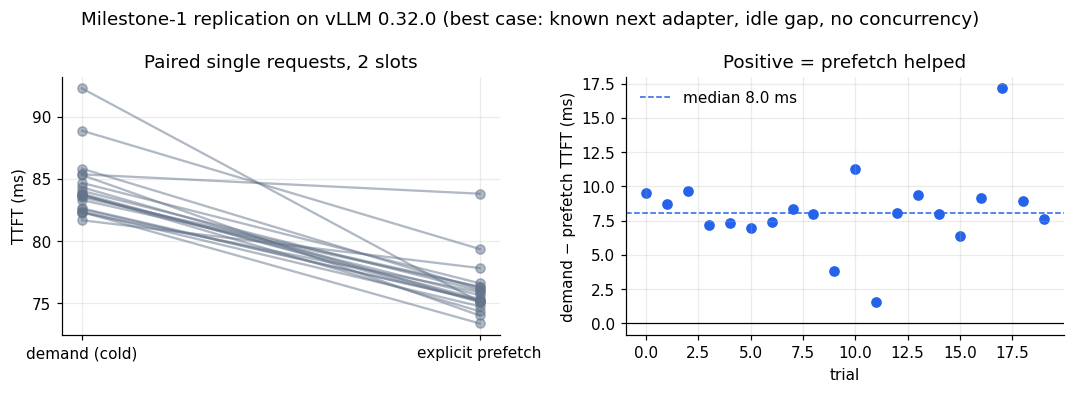

In [22]:
def bootstrap_ci(values, stat=np.median, draws=4000, seed=7):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    boots = [stat(rng.choice(values, len(values))) for _ in range(draws)]
    return float(np.quantile(boots, 0.025)), float(np.quantile(boots, 0.975))


ACTIVATION_COST_MS = None
if DIAG is not None:
    paired = DIAG.pivot(index='trial', columns='arm', values='ttft_ms')
    paired['saving_ms'] = paired['demand'] - paired['prefetch']
    lo, hi = bootstrap_ci(paired['saving_ms'])
    ACTIVATION_COST_MS = float(paired['saving_ms'].median())
    act = DIAG[DIAG.arm == 'demand']
    print(f"Median TTFT  demand {paired['demand'].median():.1f} ms | prefetch {paired['prefetch'].median():.1f} ms")
    print(f'Median paired saving {ACTIVATION_COST_MS:.2f} ms (95% bootstrap CI {lo:.2f} to {hi:.2f}); '
          f'milestone 1 (vLLM 0.11, 3 adapters) measured ~7.8 ms')
    print(f"Activation host time (demand arm) median {act.activation_host_ms.median():.2f} ms; "
          f"prefetch add_lora call median {DIAG.prefetch_control_ms.median():.2f} ms")
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
    for _, r in paired.iterrows():
        axes[0].plot([0, 1], [r['demand'], r['prefetch']], marker='o', color='#64748b', alpha=0.5)
    axes[0].set_xticks([0, 1], ['demand (cold)', 'explicit prefetch'])
    axes[0].set_ylabel('TTFT (ms)')
    axes[0].set_title('Paired single requests, 2 slots')
    axes[1].scatter(paired.index, paired['saving_ms'], color='#2563eb')
    axes[1].axhline(0, color='black', lw=0.8)
    axes[1].axhline(ACTIVATION_COST_MS, color='#2563eb', ls='--', lw=1, label=f'median {ACTIVATION_COST_MS:.1f} ms')
    axes[1].set_xlabel('trial')
    axes[1].set_ylabel('demand − prefetch TTFT (ms)')
    axes[1].legend(frameon=False)
    axes[1].set_title('Positive = prefetch helped')
    fig.suptitle(f'Milestone-1 replication on vLLM {VLLM_VERSION} (best case: known next adapter, idle gap, no concurrency)')
    fig.tight_layout()
    savefig(fig, 'fig0_single_miss_replication')

---
# Part 6: GPU trace replay
For each slot configuration: (re)start the engine, run a short **load check**, then replay **every scenario under every policy**.
Within each scenario the policy order is randomised, so slow drift in GPU clocks or temperature can't systematically favour one policy.
After every run, all logs are rewritten to CSVs in the run folder. If Colab disconnects, the completed runs are still on disk.

**If the second engine fails to start** (memory not released in-process): use Runtime → Restart session, set
`CONFIG['slot_configs'] = [4]`, and run all cells again. Then list both run folders in `ANALYZE_RUN_DIRS` in Part 7.

In [23]:
RESULT_FILES = {k: RUN_DIR / f'{k}.csv' for k in ('runs', 'requests', 'decisions', 'activations')}


RESULTS = defaultdict(list)     # in-memory copy of everything; each CSV is rewritten in full after every run


def _jsonable(v):
    if isinstance(v, set):
        v = sorted(v)
    return json.dumps(v) if isinstance(v, (list, tuple, dict)) else v


def record(key, rows):
    """Add rows to RESULTS[key] and rewrite that CSV (columns can differ between runs, so no appending)."""
    rows = rows.to_dict('records') if isinstance(rows, pd.DataFrame) else list(rows)
    RESULTS[key].extend({k: _jsonable(v) for k, v in r.items()} for r in rows)
    pd.DataFrame(RESULTS[key]).to_csv(RESULT_FILES[key], index=False)


def load_check(lab):
    """10 s of uniform traffic under LRU: is the engine moderately loaded at mean_rate?"""
    trace = make_synthetic_trace('load_check', 999, duration_s=10.0, zipf_s=0.0)
    req, decisions, step_ms = replay(lab, trace, LRUPolicy(lab.n_slots), 'load_check')
    acts, steps, loads = lab.probe.take('load_check')
    s, _, _ = summarize_run(req, decisions, step_ms, acts, steps, loads, {})
    print(f"Load check ({lab.n_slots} slots): {s['requests']} req, busy {100 * s['busy_fraction']:.0f}% of the time, "
          f"TTFT p50 {s['ttft_p50_ms']:.0f} ms / p95 {s['ttft_p95_ms']:.0f} ms, mean step {s['step_ms_mean']:.1f} ms")
    if s['busy_fraction'] > 0.9 or s['ttft_p50_ms'] > 2000:
        print('  WARNING: the engine looks saturated at this rate. Results will be dominated by queueing. '
              'Consider lowering CONFIG["mean_rate"] and regenerating the traces.')
    elif s['busy_fraction'] < 0.2:
        print('  Note: the engine is mostly idle. Prefetching will look almost free; consider a higher mean_rate.')
    return s


ALL_RUNS = []
if HAS_GPU:
    t_start = time.perf_counter()
    run_rng = random.Random(CONFIG['seed'])
    for slots in CONFIG['slot_configs']:
        if LAB_ENGINE is None or LAB_ENGINE.n_slots != slots:
            if LAB_ENGINE is not None:
                LAB_ENGINE.shutdown()
                LAB_ENGINE = None
            LAB_ENGINE = ServingLab(slots)
        load_check(LAB_ENGINE)
        for scen in SCENARIOS:
            order = list(POLICIES)
            run_rng.shuffle(order)
            for pname in order:
                run = f'{scen}|{pname}|{slots}'
                req, decisions, step_ms = replay(LAB_ENGINE, TRACES[scen], POLICIES[pname](slots), run)
                acts, steps, loads = LAB_ENGINE.probe.take(run)
                meta = {'run': run, 'scenario': scen, 'policy': pname, 'slots': slots,
                        'order_in_scenario': order.index(pname)}
                summary, req, acts = summarize_run(req, decisions, step_ms, acts, steps, loads, meta)
                for r in decisions:
                    r.update(scenario=scen, slots=slots)
                for r in acts:
                    r.update(scenario=scen, policy=pname, slots=slots)
                req = req.assign(scenario=scen, policy=pname, slots=slots)
                record('runs', [summary])
                record('requests', req)
                record('decisions', decisions)
                record('activations', acts)
                ALL_RUNS.append(summary)
                print(f"{run:40s} p50 {summary['ttft_p50_ms']:7.1f}  p95 {summary['ttft_p95_ms']:7.1f} ms | "
                      f"hit {summary['hit_at_arrival']:.2f} | demand {summary['demand_loads']:3d} | "
                      f"prefetch {summary['prefetch_loads']:3d} (useful {summary['useful_prefetches']:3d}) | "
                      f"busy {100 * summary['busy_fraction']:3.0f}%")
    print(f'Replay finished in {(time.perf_counter() - t_start) / 60:.1f} min')
else:
    print('No GPU: skipping the replay. Part 7 can analyse an earlier run folder (set ANALYZE_RUN_DIRS).')

Load check (2 slots): 46 req, busy 97% of the time, TTFT p50 3313 ms / p95 7413 ms, mean step 118.0 ms
uniform_steady|EWMA+admission|2          p50  1826.3  p95  4100.6 ms | hit 0.19 | demand  70 | prefetch   1 (useful   0) | busy  99%
uniform_steady|LRU|2                     p50  1838.9  p95  4040.3 ms | hit 0.20 | demand  70 | prefetch   0 (useful   0) | busy  99%
uniform_steady|EWMA|2                    p50  1799.8  p95  4677.5 ms | hit 0.24 | demand 356 | prefetch 275 (useful  26) | busy  95%
skewed_steady|EWMA+admission|2           p50   434.0  p95  4645.9 ms | hit 0.48 | demand  47 | prefetch   2 (useful   1) | busy  99%
skewed_steady|LRU|2                      p50   425.1  p95  4738.4 ms | hit 0.47 | demand  48 | prefetch   0 (useful   0) | busy  99%
skewed_steady|EWMA|2                     p50   446.4  p95  5810.3 ms | hit 0.44 | demand 324 | prefetch 201 (useful  14) | busy  96%
skewed_bursty|EWMA|2                     p50  1341.3  p95  7713.5 ms | hit 0.40 | demand 281 | pref

Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]


(MainProcess pid=730) WARNING 11-02 22:40:26 [utils.py:333] Attempted to load weight embed_tokens.weight with dtype torch.bfloat16 into parameter with dtype torch.float16
(MainProcess pid=730) WARNING 11-02 22:40:27 [utils.py:333] Attempted to load weight layers.0.input_layernorm.weight with dtype torch.bfloat16 into parameter with dtype torch.float16
(MainProcess pid=730) WARNING 11-02 22:40:27 [utils.py:333] Attempted to load weight layers.0.mlp.down_proj.weight with dtype torch.bfloat16 into parameter with dtype torch.float16
(MainProcess pid=730) WARNING 11-02 22:40:27 [utils.py:333] Attempted to load weight layers.0.post_attention_layernorm.weight with dtype torch.bfloat16 into parameter with dtype torch.float16
(MainProcess pid=730) WARNING 11-02 22:40:27 [utils.py:333] Attempted to load weight layers.0.self_attn.o_proj.weight with dtype torch.bfloat16 into parameter with dtype torch.float16
(MainProcess pid=730) WARNING 11-02 22:40:27 [utils.py:333] Attempted to load weight laye

---
# Part 7: Results
### 7.1 Load results and run the validity checks
By default this analyses the run that just finished. To combine sessions (for example, the 4-slot engine ran after a restart), add older
folders from `lora_cache_lab/results/` to `ANALYZE_RUN_DIRS`.

**Check the validity table before interpreting any latency.** A failed check means the measurement is wrong, not that a policy is bad.

In [24]:
ANALYZE_RUN_DIRS = [RUN_DIR]     # e.g. [RUN_DIR, LAB / 'results' / 'm2_20261105T101500Z']


def load_results(run_dirs):
    out = {}
    for key in ('runs', 'requests', 'decisions', 'activations'):
        frames = [pd.read_csv(Path(d) / f'{key}.csv') for d in run_dirs if (Path(d) / f'{key}.csv').exists()]
        out[key] = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
    return out


R = load_results(ANALYZE_RUN_DIRS)
RUNS, REQS = R['runs'], R['requests']
HAVE_GPU_RESULTS = len(RUNS) > 0
if not HAVE_GPU_RESULTS:
    print('No GPU replay results found in', [str(d) for d in ANALYZE_RUN_DIRS])
else:
    RUNS['policy'] = pd.Categorical(RUNS['policy'], POLICY_ORDER, ordered=True)
    checks = []

    def check(name, passed, detail=''):
        checks.append({'check': name, 'passed': bool(passed), 'detail': detail})

    check('every request completed', (RUNS.completed == RUNS.requests).all())
    check('every request produced exactly output_tokens tokens', RUNS.tokens_ok.astype(bool).all())
    check('no CPU/disk adapter reloads during replays', RUNS.cpu_reloads.sum() == 0, f'{int(RUNS.cpu_reloads.sum())} reloads')
    check('GPU never held more adapters than slots', (RUNS.max_resident <= RUNS.slots).all())
    check('LRU runs made zero prefetches', (RUNS[RUNS.policy == 'LRU'].prefetch_loads == 0).all())
    check('every prefetch classified useful or wasted',
          (RUNS.useful_prefetches + RUNS.wasted_prefetches == RUNS.prefetch_loads).all())
    check('all policies replayed identical traces (same request count per scenario and slots)',
          RUNS.groupby(['scenario', 'slots']).requests.nunique().eq(1).all())
    for c in DIAG_CHECKS:
        check(c['check'], c['passed'])
    CHECKS = pd.DataFrame(checks)
    CHECKS.to_csv(RUN_DIR / 'validity_checks.csv', index=False)
    display(CHECKS)
    if not CHECKS.passed.all():
        print('A validity check FAILED. Investigate before using any numbers below.')

,check,passed,detail
0,every request completed,True,
1,every request produced exactly output_tokens t...,True,
2,no CPU/disk adapter reloads during replays,True,0 reloads
3,GPU never held more adapters than slots,True,
4,LRU runs made zero prefetches,True,
5,every prefetch classified useful or wasted,True,
6,all policies replayed identical traces (same r...,True,
7,forced sequence evicts adapter 2 (the LRU),True,
8,forced sequence: last request is a GPU hit,True,
9,diagnostic: no CPU/disk reloads,True,


### 7.2 Main results table
One row per scenario × slots × policy. The columns are grouped as follows:
* **Latency:** TTFT p50, p95 and p99 in ms, measured from scheduled arrival.
* **Cache behaviour:** hit at arrival, demand loads, and prefetch-induced loads.
* **Prefetch accounting:** prefetches, useful, wasted, and wasted MB.
* **Load:** how much of the run time the engine spent inside `step()`.

`Δp95 vs LRU` is the change in p95 TTFT relative to LRU on the same trace and slots, with a request-level bootstrap 95% CI.
Negative values mean the policy was faster. The CI treats requests as independent, which they are not entirely,
so read it as indicative only. Repeated sessions (proposal §4.5, week 7) are the proper fix.

In [25]:
def p95_diff_ci(a, b, draws=2000, seed=7):
    rng = np.random.default_rng(seed)
    a, b = np.asarray(a, float), np.asarray(b, float)
    d = [np.quantile(rng.choice(a, len(a)), .95) - np.quantile(rng.choice(b, len(b)), .95) for _ in range(draws)]
    return np.quantile(d, .025), np.quantile(d, .975)


if HAVE_GPU_RESULTS:
    rows = []
    for (scen, slots), g in REQS.groupby(['scenario', 'slots']):
        base = g[g.policy == 'LRU'].ttft_ms.dropna()
        for pol, gp in g.groupby('policy'):
            if pol == 'LRU' or base.empty:
                continue
            lo, hi = p95_diff_ci(gp.ttft_ms.dropna(), base)
            rows.append({'scenario': scen, 'slots': slots, 'policy': pol,
                         'dp95_vs_lru_ms': gp.ttft_ms.quantile(.95) - base.quantile(.95),
                         'dp95_ci_lo': lo, 'dp95_ci_hi': hi})
    DELTAS = pd.DataFrame(rows, columns=['scenario', 'slots', 'policy', 'dp95_vs_lru_ms', 'dp95_ci_lo', 'dp95_ci_hi'])
    TABLE = RUNS.merge(DELTAS, on=['scenario', 'slots', 'policy'], how='left')
    TABLE['scenario'] = pd.Categorical(TABLE['scenario'], [s for s in SCENARIOS if s in set(TABLE.scenario)] or None)
    cols = ['slots', 'scenario', 'policy', 'requests', 'ttft_p50_ms', 'ttft_p95_ms', 'ttft_p99_ms', 'dp95_vs_lru_ms',
            'dp95_ci_lo', 'dp95_ci_hi', 'hit_at_arrival', 'demand_loads', 'prefetch_induced_loads', 'prefetch_loads',
            'useful_prefetches', 'wasted_prefetches', 'wasted_MB', 'busy_fraction']
    TABLE = TABLE.sort_values(['slots', 'scenario', 'policy'])[cols]
    TABLE.to_csv(RUN_DIR / 'results_table.csv', index=False)
    display(TABLE.round(2).set_index(['slots', 'scenario', 'policy']))

requests  ttft_p50_ms  ttft_p95_ms  ttft_p99_ms  dp95_vs_lru_ms  dp95_ci_lo  dp95_ci_hi  hit_at_arrival  demand_loads  \
slots scenario       policy                                                                                                                                  
2     uniform_steady EWMA                 185      1799.84      4677.54      5481.01          637.25     -397.70     1027.58            0.24           356   
                     EWMA+admission       185      1826.31      4100.56      5920.67           60.27    -1018.78     1075.17            0.19            70   
                     LRU                  185      1838.87      4040.29      5914.63             NaN         NaN         NaN            0.20            70   
      skewed_steady  EWMA                 185       446.37      5810.32      9803.80         1071.89     -282.58     3164.28            0.44           324   
                     EWMA+admission       185       433.97      4645.88      6911.80          -92.55    -1383.91     1368.45            0.48            47   
                     LRU                  185       425.06      4738.43      6915.34             NaN         NaN         NaN            0.47            48   
      skewed_bursty  EWMA                 232      1341.26      7713.46      8656.15          427.42     -314.53     1496.34            0.40           281   
                     EWMA+admission       232      1283.80      7339.33      8360.31           53.28    -1148.51     1187.33            0.36            44   
                     LRU                  232      1279.83      7286.04      8346.78             NaN         NaN         NaN            0.36            46   
      skewed_local   EWMA                 185       473.62      3147.77      3876.82         1005.48      517.17     1447.11            0.43           299   
                     EWMA+admission       185       717.22      1909.67      2836.44         -232.62     -620.62      304.26            0.38            58   
                     LRU                  185       629.60      2142.29      2883.03             NaN         NaN         NaN            0.41            54   
      drift_abrupt   EWMA                 185       741.07      3830.17      4445.12          -84.88    -1013.33      565.76            0.47           292   
                     EWMA+admission       185       714.31      3925.54      4967.22           10.48     -880.24      787.86            0.45            55   
                     LRU                  185       753.54      3915.06      4938.78             NaN         NaN         NaN            0.43            54   
      drift_gradual  EWMA                 185      1190.11      4013.31      4517.42           88.17     -468.15      686.14            0.39           298   
                     EWMA+admission       185      1078.02      4270.02      4897.79          344.89     -353.47     1151.09            0.38            58   
                     LRU                  185      1165.94      3925.13      4726.21             NaN         NaN         NaN            0.36            58   
      azure_2021     EWMA                 190       130.92      1902.16      2246.08          149.45     -418.90      723.98            0.65           164   
                     EWMA+admission       190       126.94      1748.35      2107.05           -4.36     -533.21      569.95            0.62            39   
                     LRU                  190       134.47      1752.71      2140.24             NaN         NaN         NaN            0.62            39   
4     uniform_steady EWMA                 185       143.06      1166.03      1380.20          274.78       83.43      500.98            0.49           462   
                     EWMA+admission       185       129.12       908.13      1101.72           16.89     -204.94      214.45            0.50            86   
                     LRU                  185       127.55       891.25      1114.70   

### 7.3 Figure 1: tail latency by scenario
This is the headline figure. Bars show **p95 TTFT** and dots show **p50**. Compare the three bars inside each scenario group.
Questions to answer: in which scenarios do the predictors lower the tail? In which do they raise it? Does adding admission control fix the regressions?

saved figure: results/m2_20261102T221446Z/figures/fig1_ttft_by_scenario.png


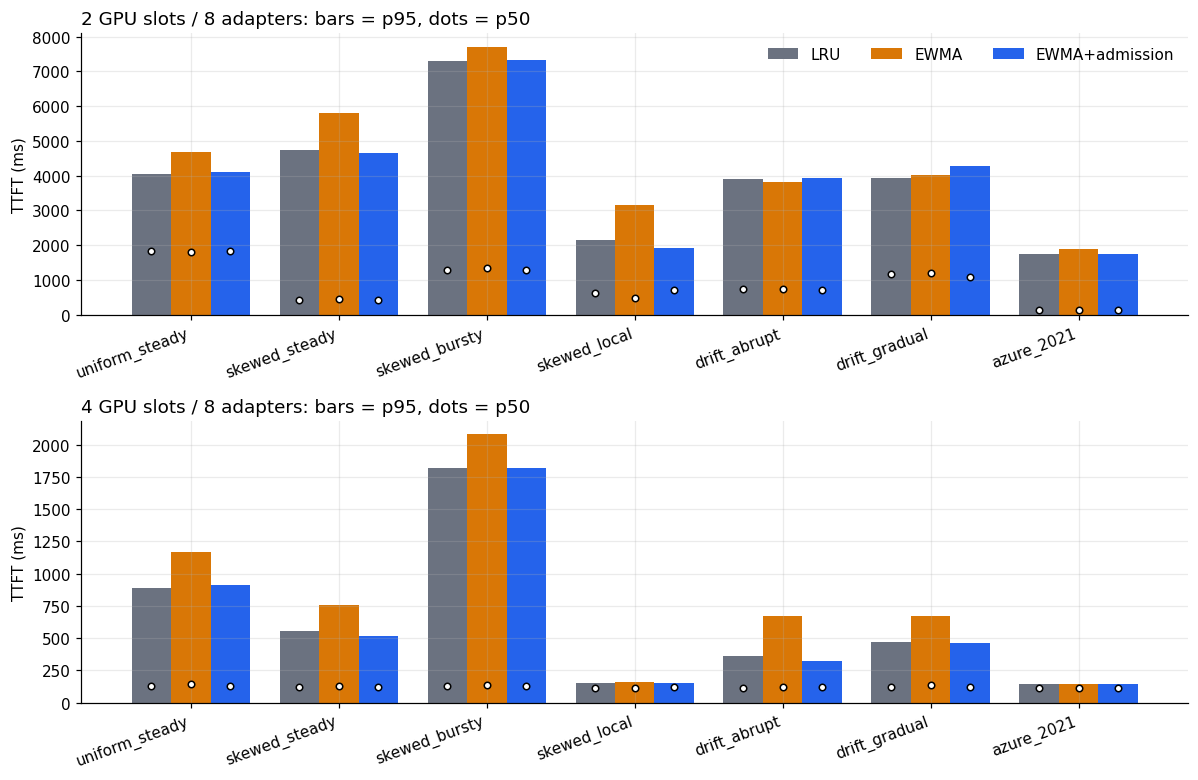

In [26]:
if HAVE_GPU_RESULTS:
    slot_list = sorted(RUNS.slots.unique())
    fig, axes = plt.subplots(len(slot_list), 1, figsize=(11, 3.6 * len(slot_list)), squeeze=False)
    for ax, slots in zip(axes[:, 0], slot_list):
        sub = RUNS[RUNS.slots == slots]
        grouped_bars(ax, sub, 'ttft_p95_ms', ylabel='TTFT (ms)')
        scen = [s for s in SCENARIOS if s in set(sub.scenario)]
        width = 0.8 / len(POLICY_ORDER)
        for i, pol in enumerate(POLICY_ORDER):
            p = sub[sub.policy == pol].set_index('scenario').reindex(scen)
            ax.scatter(np.arange(len(scen)) + (i - 1) * width, p.ttft_p50_ms, color='white', edgecolor='black', zorder=3, s=18)
        ax.set_title(f'{slots} GPU slots / {CONFIG["n_adapters"]} adapters: bars = p95, dots = p50', loc='left')
    axes[0, 0].legend(frameon=False, ncol=3)
    fig.tight_layout()
    savefig(fig, 'fig1_ttft_by_scenario')

### 7.4 Figure 2: where the latency comes from
On the left is **hit at arrival**, which is what prediction is supposed to raise. On the right are **demand loads per 100 requests**, split into
ordinary misses and misses **caused by a prefetch** that evicted something still needed (hatched).
A predictor that raises the hit rate but also causes many induced loads is trading one kind of miss for another.

saved figure: results/m2_20261102T221446Z/figures/fig2_hits_and_loads.png


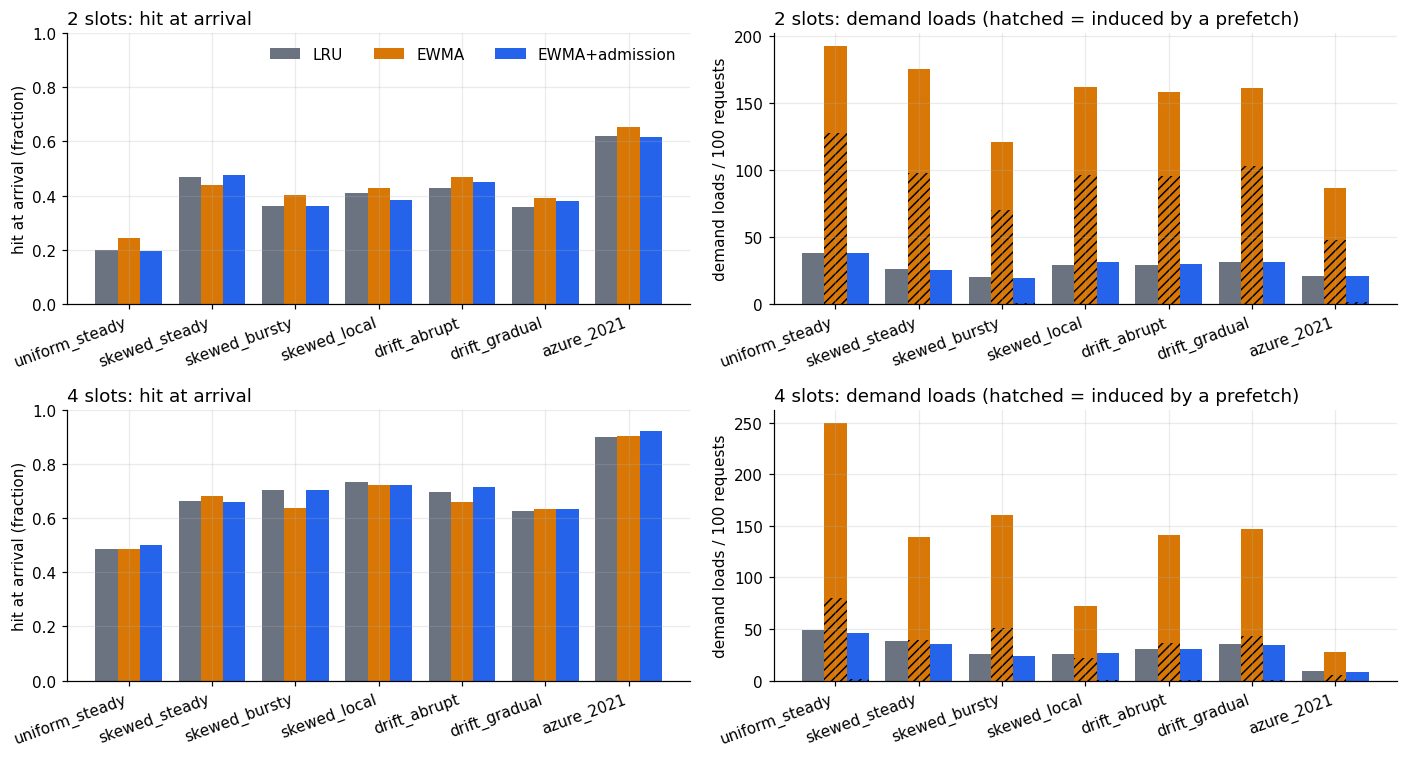

In [27]:
if HAVE_GPU_RESULTS:
    slot_list = sorted(RUNS.slots.unique())
    fig, axes = plt.subplots(len(slot_list), 2, figsize=(13, 3.5 * len(slot_list)), squeeze=False)
    for row, slots in enumerate(slot_list):
        sub = RUNS[RUNS.slots == slots].copy()
        sub['demand_per100'] = 100 * sub.demand_loads / sub.requests
        sub['induced_per100'] = 100 * sub.prefetch_induced_loads / sub.requests
        grouped_bars(axes[row, 0], sub, 'hit_at_arrival', ylabel='hit at arrival (fraction)')
        axes[row, 0].set_ylim(0, 1)
        axes[row, 0].set_title(f'{slots} slots: hit at arrival', loc='left')
        grouped_bars(axes[row, 1], sub, 'demand_per100', ylabel='demand loads / 100 requests')
        scen = [s for s in SCENARIOS if s in set(sub.scenario)]
        width = 0.8 / len(POLICY_ORDER)
        for i, pol in enumerate(POLICY_ORDER):
            p = sub[sub.policy == pol].set_index('scenario').reindex(scen)
            axes[row, 1].bar(np.arange(len(scen)) + (i - 1) * width, p.induced_per100, width, fill=False,
                             hatch='////', edgecolor='black', lw=0)
        axes[row, 1].set_title(f'{slots} slots: demand loads (hatched = induced by a prefetch)', loc='left')
    axes[0, 0].legend(frameon=False, ncol=3)
    fig.tight_layout()
    savefig(fig, 'fig2_hits_and_loads')

### 7.5 Figure 3: prefetch accounting
For the two predictors, each bar splits prefetches into **useful** (solid) and **wasted** (light), per 100 requests. The number above each bar is wasted MB.
Admission control should cut the wasted part much more than the useful part. If it cuts both equally, it is just throttling.

saved figure: results/m2_20261102T221446Z/figures/fig3_prefetch_accounting.png


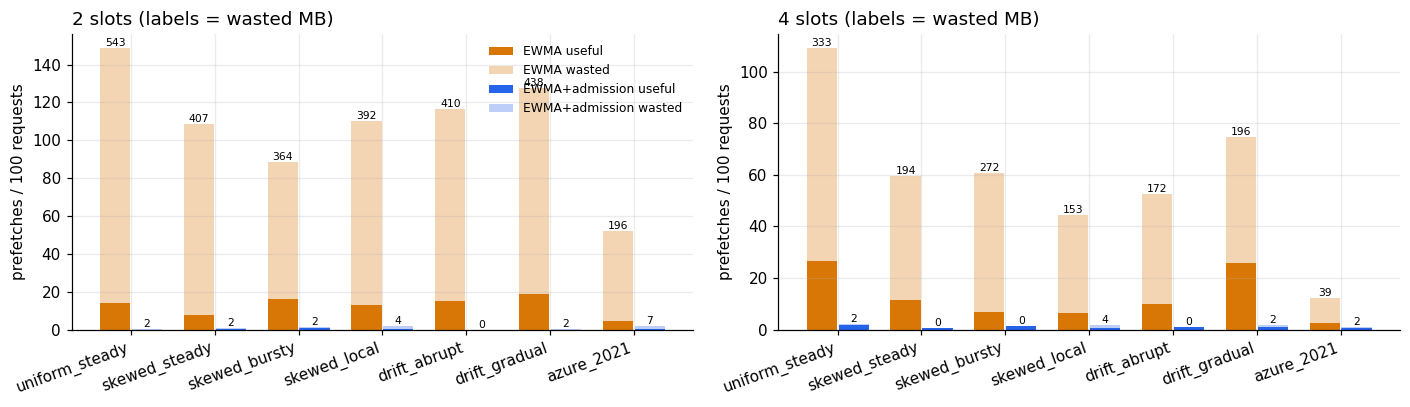

Why EWMA+admission accepted or rejected candidate prefetches (counts):


reason                R1_victim_in_use  R2_low_benefit  R3_busy  R4_budget  admitted
slots scenario                                                                      
2     azure_2021                    11               2       68          0         4
      drift_abrupt                   7               5      163          0         0
      drift_gradual                  7               0      174          0         1
      skewed_bursty                 20               3      145          0         3
      skewed_local                  19               1      147          0         3
      skewed_steady                 17               0      152          0         2
      uniform_steady                 4               3      241          0         1
4     azure_2021                     4               6       21          0         2
      drift_abrupt                  14              19       59          0         2
      drift_gradual                 16               9       64          0         3
      skewed_bursty                  6              18      102          0         3
      skewed_local                  12              33       48          0         3
      skewed_steady                 12              28       67          0         1
      uniform_steady                17              29      104          1         4

In [28]:
if HAVE_GPU_RESULTS:
    slot_list = sorted(RUNS.slots.unique())
    preds = ['EWMA', 'EWMA+admission']
    fig, axes = plt.subplots(1, len(slot_list), figsize=(6.5 * len(slot_list), 3.8), squeeze=False)
    for ax, slots in zip(axes[0], slot_list):
        sub = RUNS[(RUNS.slots == slots) & RUNS.policy.isin(preds)]
        scen = [s for s in SCENARIOS if s in set(sub.scenario)]
        x = np.arange(len(scen))
        for i, pol in enumerate(preds):
            p = sub[sub.policy == pol].set_index('scenario').reindex(scen)
            useful = 100 * p.useful_prefetches / p.requests
            wasted = 100 * p.wasted_prefetches / p.requests
            xs = x + (i - 0.5) * 0.38
            ax.bar(xs, useful, 0.36, color=POLICY_COLORS[pol], label=f'{pol} useful')
            ax.bar(xs, wasted, 0.36, bottom=useful, color=POLICY_COLORS[pol], alpha=0.3, label=f'{pol} wasted')
            for xi, top, mb in zip(xs, useful + wasted, p.wasted_MB):
                ax.text(xi, top, f'{mb:.0f}', ha='center', va='bottom', fontsize=7)
        ax.set_xticks(x, scen, rotation=20, ha='right')
        ax.set_ylabel('prefetches / 100 requests')
        ax.set_title(f'{slots} slots (labels = wasted MB)', loc='left')
    axes[0, 0].legend(frameon=False, fontsize=8)
    fig.tight_layout()
    savefig(fig, 'fig3_prefetch_accounting')

    DEC = R['decisions']
    if len(DEC):
        adm = DEC[DEC.policy == 'EWMA+admission']
        if len(adm):
            print('Why EWMA+admission accepted or rejected candidate prefetches (counts):')
            display(pd.crosstab([adm.slots, adm.scenario], adm.reason))

### 7.6 Figure 4: full TTFT distribution for one scenario
A CDF shows whether a policy shifts the whole distribution or only the tail. The default is `skewed_bursty`; change `CDF_SCENARIO` to look at another.

saved figure: results/m2_20261102T221446Z/figures/fig4_ttft_cdf.png


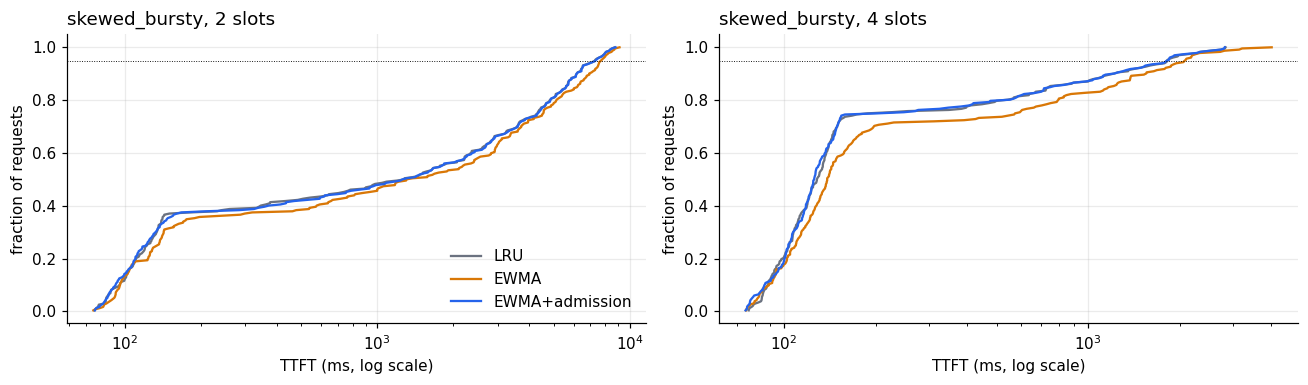

In [29]:
CDF_SCENARIO = 'skewed_bursty' if 'skewed_bursty' in SCENARIOS else (SCENARIOS[0] if SCENARIOS else None)
if HAVE_GPU_RESULTS and CDF_SCENARIO in set(REQS.scenario):
    slot_list = sorted(REQS.slots.unique())
    fig, axes = plt.subplots(1, len(slot_list), figsize=(6 * len(slot_list), 3.6), squeeze=False)
    for ax, slots in zip(axes[0], slot_list):
        for pol in POLICY_ORDER:
            v = np.sort(REQS[(REQS.scenario == CDF_SCENARIO) & (REQS.slots == slots) & (REQS.policy == pol)].ttft_ms.dropna())
            if len(v):
                ax.plot(v, np.arange(1, len(v) + 1) / len(v), color=POLICY_COLORS[pol], label=pol)
        ax.axhline(0.95, color='black', lw=0.6, ls=':')
        ax.set_xscale('log')
        ax.set_xlabel('TTFT (ms, log scale)')
        ax.set_ylabel('fraction of requests')
        ax.set_title(f'{CDF_SCENARIO}, {slots} slots', loc='left')
    axes[0, 0].legend(frameon=False)
    fig.tight_layout()
    savefig(fig, 'fig4_ttft_cdf')

### 7.7 Figure 5: drift recovery (research question 2)
Hit at arrival over time in 3-second bins, for the drift scenarios. The dashed line marks where the popularity ranking starts to reverse.
**Recovery time** is the time from the drift start until the 3-bin rolling hit rate first gets back to 90% of its pre-drift average. It is printed below the figure.

saved figure: results/m2_20261102T221446Z/figures/fig5_drift_recovery.png


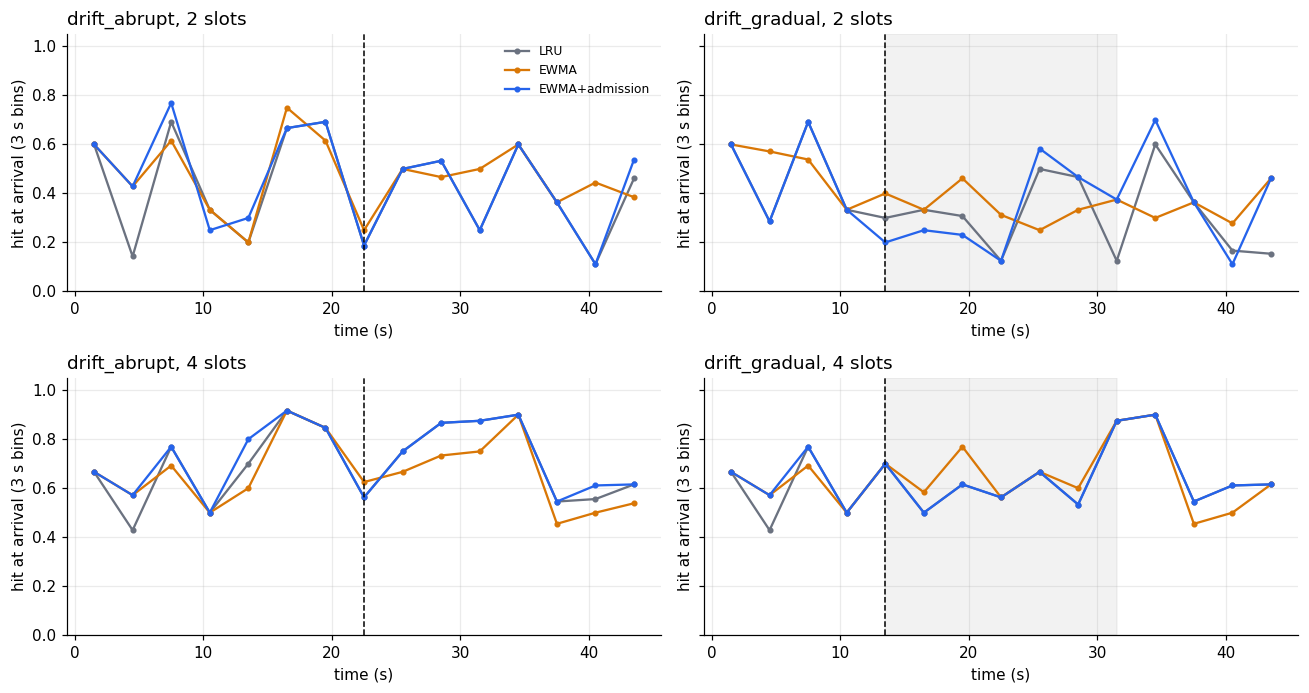

policy               EWMA  EWMA+admission  LRU
scenario      slots                           
drift_abrupt  2      10.5             NaN  4.5
              4       4.5             4.5  4.5
drift_gradual 2       NaN            19.5  NaN
              4       4.5             4.5  4.5

In [30]:
def recovery_time(sub, drift_start, bin_s=3.0):
    t = np.floor(sub.arrival_s / bin_s) * bin_s
    series = sub.groupby(t).resident_at_arrival.mean()
    pre = series[series.index + bin_s <= drift_start].mean()
    roll = series.rolling(3, min_periods=1).mean()
    after = roll[roll.index >= drift_start]
    ok = after[after >= 0.9 * pre]
    return (float(ok.index[0] + bin_s - drift_start) if len(ok) else np.nan), series, pre


DRIFT_SCENARIOS = [s for s in ['drift_abrupt', 'drift_gradual'] if s in SCENARIOS]
if HAVE_GPU_RESULTS and DRIFT_SCENARIOS:
    slot_list = sorted(REQS.slots.unique())
    fig, axes = plt.subplots(len(slot_list), len(DRIFT_SCENARIOS), figsize=(6 * len(DRIFT_SCENARIOS), 3.2 * len(slot_list)),
                             squeeze=False, sharey=True)
    rec_rows = []
    for r_i, slots in enumerate(slot_list):
        for c_i, scen in enumerate(DRIFT_SCENARIOS):
            ax = axes[r_i, c_i]
            start = SCENARIO_SPECS[scen]['drift']['at_frac'] * CONFIG['duration_s']
            for pol in POLICY_ORDER:
                sub = REQS[(REQS.scenario == scen) & (REQS.slots == slots) & (REQS.policy == pol)]
                if not len(sub):
                    continue
                rec, series, pre = recovery_time(sub, start)
                ax.plot(series.index + 1.5, series.values, marker='.', color=POLICY_COLORS[pol], label=pol)
                rec_rows.append({'scenario': scen, 'slots': slots, 'policy': pol,
                                 'pre_drift_hit': round(pre, 3), 'recovery_s': rec})
            ax.axvline(start, color='black', ls='--', lw=1)
            if scen == 'drift_gradual':
                ax.axvspan(start, SCENARIO_SPECS[scen]['drift']['end_frac'] * CONFIG['duration_s'], color='gray', alpha=0.1)
            ax.set_title(f'{scen}, {slots} slots', loc='left')
            ax.set_xlabel('time (s)')
            ax.set_ylabel('hit at arrival (3 s bins)')
            ax.set_ylim(0, 1.05)
    axes[0, 0].legend(frameon=False, fontsize=8)
    fig.tight_layout()
    savefig(fig, 'fig5_drift_recovery')
    RECOVERY = pd.DataFrame(rec_rows)
    RECOVERY.to_csv(RUN_DIR / 'drift_recovery.csv', index=False)
    display(RECOVERY.pivot_table(index=['scenario', 'slots'], columns='policy', values='recovery_s', observed=False, dropna=False))

### 7.8 Figure 6: does the CPU simulator agree with the GPU?
Each point is one scenario × policy × slots cell. The x-axis is the simulator's hit at arrival **on the identical trace**, and the y-axis is the GPU's.
Points near the diagonal mean the simulator's counts are trustworthy, so its sweeps (Figures S2 and S3) are good evidence too.
Expect GPU hit rates to sit slightly **above** the line. On the GPU, a burst of same-adapter requests waits for one load,
and adapters stay resident while requests are queued, which the simulator does not model.

saved figure: results/m2_20261102T221446Z/figures/fig6_sim_vs_gpu.png


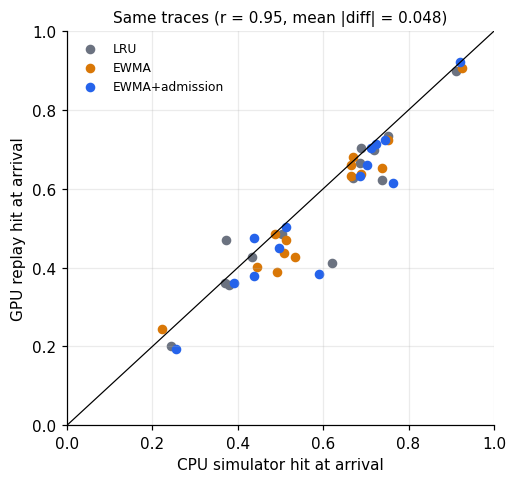

In [31]:
if HAVE_GPU_RESULTS:
    pts = []
    for r in RUNS.itertuples():
        if r.scenario not in TRACES:
            continue
        s, _ = simulate(TRACES[r.scenario], POLICIES[r.policy](int(r.slots)))
        pts.append({'scenario': r.scenario, 'policy': r.policy, 'slots': r.slots, 'sim': s['hit_rate'], 'gpu': r.hit_at_arrival})
    PTS = pd.DataFrame(pts)
    if len(PTS):
        fig, ax = plt.subplots(figsize=(4.8, 4.5))
        for pol in POLICY_ORDER:
            p = PTS[PTS.policy == pol]
            ax.scatter(p.sim, p.gpu, color=POLICY_COLORS[pol], label=pol, s=28)
        ax.plot([0, 1], [0, 1], color='black', lw=0.8)
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_xlabel('CPU simulator hit at arrival')
        ax.set_ylabel('GPU replay hit at arrival')
        corr = np.corrcoef(PTS.sim, PTS.gpu)[0, 1] if len(PTS) > 2 else np.nan
        ax.set_title(f'Same traces (r = {corr:.2f}, mean |diff| = {np.mean(np.abs(PTS.sim - PTS.gpu)):.3f})', fontsize=10)
        ax.legend(frameon=False, fontsize=8)
        fig.tight_layout()
        savefig(fig, 'fig6_sim_vs_gpu')

### 7.9 Auto-written initial findings
The cell below turns the numbers into plain sentences. They are **generated from this run's data**, so they stay honest if the results change.
It writes `findings.md` into the run folder. Edit the wording for slides, but keep the numbers.

In [32]:
def fmt_ms(x):
    return f'{x:+.0f} ms' if abs(x) >= 1 else f'{x:+.1f} ms'


def findings_markdown():
    L = [f'# Initial findings (run `{RUN_DIR.name}`)', '',
         f'Setup: {CONFIG["model_id"]} on {GPU_SUMMARY or "(no GPU)"}, vLLM {VLLM_VERSION}, '
         f'{CONFIG["n_adapters"]} rank-{CONFIG["rank"]} adapters, slots {sorted(int(x) for x in RUNS.slots.unique()) if HAVE_GPU_RESULTS else "-"}, '
         f'{CONFIG["duration_s"]:.0f} s traces at {CONFIG["mean_rate"]} req/s mean, up to {CONFIG["max_num_seqs"]} concurrent.', '']
    if ACTIVATION_COST_MS is not None:
        L += [f'- **Single-miss cost (milestone-1 replication):** one avoided activation saves a median '
              f'{ACTIVATION_COST_MS:.1f} ms of TTFT in the best case (milestone 1 on vLLM 0.11: ~7.8 ms).', '']
    if not HAVE_GPU_RESULTS:
        L.append('- No GPU replay results yet; simulator results only.')
    else:
        L.append('**Per scenario (Δ = policy minus LRU on the identical trace):**')
        L.append('')
        L.append('| slots | scenario | LRU p95 | EWMA Δp95 | EWMA+adm Δp95 | LRU hit | EWMA hit | EWMA+adm hit | EWMA wasted | EWMA+adm wasted |')
        L.append('|---|---|---|---|---|---|---|---|---|---|')
        helped, hurt, fixed = [], [], []
        for slots in sorted(RUNS.slots.unique()):
            for scen in [s for s in SCENARIOS if s in set(RUNS.scenario)]:
                g = RUNS[(RUNS.slots == slots) & (RUNS.scenario == scen)].set_index('policy')
                if 'LRU' not in g.index:
                    continue
                base = g.loc['LRU']
                cell = {p: g.loc[p] for p in ['EWMA', 'EWMA+admission'] if p in g.index}
                d = {p: c.ttft_p95_ms - base.ttft_p95_ms for p, c in cell.items()}
                L.append(f"| {slots} | {scen} | {base.ttft_p95_ms:.0f} ms | "
                         f"{fmt_ms(d['EWMA']) if 'EWMA' in d else '-'} | {fmt_ms(d['EWMA+admission']) if 'EWMA+admission' in d else '-'} | "
                         f"{base.hit_at_arrival:.2f} | {cell['EWMA'].hit_at_arrival if 'EWMA' in cell else float('nan'):.2f} | "
                         f"{cell['EWMA+admission'].hit_at_arrival if 'EWMA+admission' in cell else float('nan'):.2f} | "
                         f"{int(cell['EWMA'].wasted_prefetches) if 'EWMA' in cell else '-'} | "
                         f"{int(cell['EWMA+admission'].wasted_prefetches) if 'EWMA+admission' in cell else '-'} |")
                thr = max(0.05 * base.ttft_p95_ms, 2.0)  # ignore differences under 5% (or 2 ms) as noise
                for p, dv in d.items():
                    if dv < -thr:
                        helped.append(f'{p} in {scen} ({slots} slots, {fmt_ms(dv)} p95)')
                    elif dv > thr:
                        hurt.append(f'{p} in {scen} ({slots} slots, {fmt_ms(dv)} p95)')
                if 'EWMA' in d and 'EWMA+admission' in d and d['EWMA'] > thr and d['EWMA+admission'] <= thr:
                    fixed.append(f'{scen} ({slots} slots)')
        L += ['', f'- **Prediction helped the tail (≥5% lower p95):** {"; ".join(helped) if helped else "nowhere in this run"}.',
              f'- **Prediction hurt the tail (≥5% higher p95):** {"; ".join(hurt) if hurt else "nowhere in this run"}.',
              f'- **Admission control removed an EWMA regression in:** {", ".join(fixed) if fixed else "no scenario"}.']
        tot = RUNS.groupby('policy', observed=True)[['prefetch_loads', 'wasted_prefetches', 'wasted_MB', 'prefetch_induced_loads']].sum()
        for p in ['EWMA', 'EWMA+admission']:
            if p in tot.index and tot.loc[p, 'prefetch_loads'] > 0:
                t = tot.loc[p]
                L.append(f'- **{p}:** {int(t.prefetch_loads)} prefetches overall, {100 * t.wasted_prefetches / t.prefetch_loads:.0f}% wasted '
                         f'({t.wasted_MB:.0f} MB moved for nothing), {int(t.prefetch_induced_loads)} demand loads caused by prefetch evictions.')
        if 'RECOVERY' in globals() and len(RECOVERY):
            rec = RECOVERY.groupby('policy').recovery_s.median()
            L.append('- **Drift recovery (median over drift scenarios and slots):** ' +
                     ', '.join(f'{p} {v:.0f} s' if pd.notna(v) else f'{p} did not recover' for p, v in rec.items()) + '.')
    if 'SWEEP' in globals():
        s = SWEEP.copy()
        base = s[s.policy == 'LRU'].set_index(['zipf_s', 'p_repeat', 'seed']).hit_rate
        g = s[s.policy == 'EWMA+admission'].set_index(['zipf_s', 'p_repeat', 'seed']).hit_rate - base
        cell = g.groupby(level=[0, 1]).mean()
        best = cell.idxmax()
        L.append(f'- **Simulator sweep:** EWMA+admission gains the most hit rate at Zipf s = {best[0]}, locality {best[1]} '
                 f'({100 * cell.max():+.1f} pp vs LRU) and the least at s = {cell.idxmin()[0]}, locality {cell.idxmin()[1]} '
                 f'({100 * cell.min():+.1f} pp).')
    L += ['', '**Caveats:** single GPU session; synthetic untrained adapters (~2 MB each); async scheduling and CUDA graphs off; '
          'Azure functions used as stand-ins for adapters; request-level bootstrap CIs are optimistic.']
    return '\n'.join(L)


FINDINGS = findings_markdown()
(RUN_DIR / 'findings.md').write_text(FINDINGS)
display(Markdown(FINDINGS))

# Initial findings (run `m2_20261102T221446Z`)

Setup: Qwen/Qwen2.5-1.5B-Instruct on NVIDIA L4, 23034 MiB, 580.82.07, vLLM 0.32.0, 8 rank-8 adapters, slots [2, 4], 45 s traces at 4.0 req/s mean, up to 16 concurrent.

- **Single-miss cost (milestone-1 replication):** one avoided activation saves a median 8.0 ms of TTFT in the best case (milestone 1 on vLLM 0.11: ~7.8 ms).

**Per scenario (Δ = policy minus LRU on the identical trace):**

| slots | scenario | LRU p95 | EWMA Δp95 | EWMA+adm Δp95 | LRU hit | EWMA hit | EWMA+adm hit | EWMA wasted | EWMA+adm wasted |
|---|---|---|---|---|---|---|---|---|---|
| 2 | uniform_steady | 4040 ms | +637 ms | +60 ms | 0.20 | 0.24 | 0.19 | 249 | 1 |
| 2 | skewed_steady | 4738 ms | +1072 ms | -93 ms | 0.47 | 0.44 | 0.48 | 187 | 1 |
| 2 | skewed_bursty | 7286 ms | +427 ms | +53 ms | 0.36 | 0.40 | 0.36 | 167 | 1 |
| 2 | skewed_local | 2142 ms | +1005 ms | -233 ms | 0.41 | 0.43 | 0.38 | 180 | 2 |
| 2 | drift_abrupt | 3915 ms | -85 ms | +10 ms | 0.43 | 0.47 | 0.45 | 188 | 0 |
| 2 | drift_gradual | 3925 ms | +88 ms | +345 ms | 0.36 | 0.39 | 0.38 | 201 | 1 |
| 2 | azure_2021 | 1753 ms | +149 ms | -4 ms | 0.62 | 0.65 | 0.62 | 90 | 3 |
| 4 | uniform_steady | 891 ms | +275 ms | +17 ms | 0.49 | 0.49 | 0.50 | 153 | 1 |
| 4 | skewed_steady | 557 ms | +197 ms | -37 ms | 0.66 | 0.68 | 0.66 | 89 | 0 |
| 4 | skewed_bursty | 1821 ms | +259 ms | +0.3 ms | 0.70 | 0.64 | 0.70 | 125 | 0 |
| 4 | skewed_local | 153 ms | +9 ms | -0.6 ms | 0.74 | 0.72 | 0.72 | 70 | 2 |
| 4 | drift_abrupt | 359 ms | +316 ms | -34 ms | 0.70 | 0.66 | 0.71 | 79 | 0 |
| 4 | drift_gradual | 469 ms | +200 ms | -4 ms | 0.63 | 0.63 | 0.63 | 90 | 1 |
| 4 | azure_2021 | 147 ms | -0.5 ms | -0.4 ms | 0.90 | 0.91 | 0.92 | 18 | 1 |

- **Prediction helped the tail (≥5% lower p95):** EWMA+admission in skewed_local (2 slots, -233 ms p95); EWMA+admission in skewed_steady (4 slots, -37 ms p95); EWMA+admission in drift_abrupt (4 slots, -34 ms p95).
- **Prediction hurt the tail (≥5% higher p95):** EWMA in uniform_steady (2 slots, +637 ms p95); EWMA in skewed_steady (2 slots, +1072 ms p95); EWMA in skewed_bursty (2 slots, +427 ms p95); EWMA in skewed_local (2 slots, +1005 ms p95); EWMA+admission in drift_gradual (2 slots, +345 ms p95); EWMA in azure_2021 (2 slots, +149 ms p95); EWMA in uniform_steady (4 slots, +275 ms p95); EWMA in skewed_steady (4 slots, +197 ms p95); EWMA in skewed_bursty (4 slots, +259 ms p95); EWMA in skewed_local (4 slots, +9 ms p95); EWMA in drift_abrupt (4 slots, +316 ms p95); EWMA in drift_gradual (4 slots, +200 ms p95).
- **Admission control removed an EWMA regression in:** uniform_steady (2 slots), skewed_steady (2 slots), skewed_bursty (2 slots), skewed_local (2 slots), azure_2021 (2 slots), uniform_steady (4 slots), skewed_steady (4 slots), skewed_bursty (4 slots), skewed_local (4 slots), drift_abrupt (4 slots), drift_gradual (4 slots).
- **EWMA:** 2229 prefetches overall, 85% wasted (4110 MB moved for nothing), 1751 demand loads caused by prefetch evictions.
- **EWMA+admission:** 32 prefetches overall, 44% wasted (31 MB moved for nothing), 9 demand loads caused by prefetch evictions.
- **Drift recovery (median over drift scenarios and slots):** EWMA 4 s, EWMA+admission 4 s, LRU 4 s.
- **Simulator sweep:** EWMA+admission gains the most hit rate at Zipf s = 1.2, locality 0.0 (+3.5 pp vs LRU) and the least at s = 0.4, locality 0.75 (-2.6 pp).

**Caveats:** single GPU session; synthetic untrained adapters (~2 MB each); async scheduling and CUDA graphs off; Azure functions used as stand-ins for adapters; request-level bootstrap CIs are optimistic.

---
# Part 8: Presenting the initial findings
### Suggested slide order (10–11 slides)
| # | Slide | Source in this notebook |
|---|---|---|
| 1 | **Question:** when does predictive LoRA prefetching beat LRU, and when does it hurt? | Background |
| 2 | **Setup:** 1.5B model, 8 adapters, 2/4 GPU slots, vLLM 0.32 in-process, concurrent replay | Background, 1.4, `environment.json` |
| 3 | **The ceiling:** one avoided miss saves ≈ X ms (milestone 1, replicated on vLLM 0.32) | `fig0_single_miss_replication` |
| 4 | **Workloads:** five factors varied independently, plus a real Azure trace | `figW1`, `figW2` |
| 5 | **Policies:** LRU vs EWMA vs EWMA+admission (show the R1–R4 table) | Part 3 |
| 6 | **Headline:** p95 TTFT by scenario | `fig1_ttft_by_scenario` |
| 7 | **Why:** hit rate up, but induced misses and wasted transfers | `fig2_hits_and_loads`, `fig3_prefetch_accounting` |
| 8 | **Drift:** how fast each policy recovers | `fig5_drift_recovery` |
| 9 | **Where prediction helps:** skew × locality map (simulator, validated against GPU) | `figS2`, `fig6_sim_vs_gpu` |
| 9b | **Cost-aware admission:** waste vs benefit trade-off | `figS4_admission_tradeoff`, the admission reason table in 7.5 |
| 10 | **Caveats and next steps** | below |

Use the sentences from `findings.md` as speaker notes. They are computed, not written by hand.

### Limitations to state honestly
* **One session, one seed per GPU cell.** GPU numbers are single runs. The simulator gives seed variability for counts but not latency.
  The proposal's week-7 plan (repeat across sessions, report uncertainty) still applies.
* **Synthetic, untrained adapters** of about 2.2 MB. Activation cost scales with adapter size. Real adapters with more target modules or a higher rank would make misses (and wasted prefetches) more expensive.
* **Async scheduling and CUDA graphs are off** for clean attribution. Production vLLM overlaps more work, so the absolute TTFTs are pessimistic.
* **Fixed prompt and output lengths** (64/16 tokens). Real length distributions (for example, from the Azure LLM inference 2024 trace) would add variance.
* **Azure functions are a stand-in for adapters,** and the trace is time-compressed and thinned. Both are modelling assumptions, not measurements of LoRA demand.
* **Prefetch only through vLLM's public `add_lora()`,** so vLLM always picks the victim by LRU. The admission policy can only steer it with touches.

### Next steps (proposal weeks 4–7)
1. Add the **transition (Markov)** and **online logistic regression** predictors. Both plug into the same `decide()` interface and run in the simulator first.
2. Add a **frequency-based baseline** (LFU-like retention) to separate "prediction" from "remembering popular adapters".
3. **Repeat GPU runs** across seeds and sessions. Report per-cell CIs over runs instead of over requests.
4. Sweep **burstiness** and **arrival rate** on the GPU, where busy-time costs (rule R3) matter most.
5. Try a larger rank or more target modules to make activations more expensive, and see whether the conclusions flip.

### Export the results bundle
This zips the run folder: config, environment, pip freeze, traces, all CSVs, figures, findings and adapter configs.
It excludes the adapter weight files (they can be regenerated from the seed) and the base model. Download it before the Colab session ends.

In [33]:
bundle = LAB / f'{RUN_DIR.name}_bundle.zip'
with zipfile.ZipFile(bundle, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
    for path in RUN_DIR.rglob('*'):
        if path.is_file() and path.suffix != '.safetensors':
            zf.write(path, Path(RUN_DIR.name) / path.relative_to(RUN_DIR))
print('Bundle:', bundle, f'({bundle.stat().st_size / 1e6:.1f} MB)')
if IN_COLAB:
    from google.colab import files
    files.download(str(bundle))

Bundle: /content/lora_cache_lab/m2_20261102T221446Z_bundle.zip (2.6 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [34]:
# Release the GPU engine when you are done (or simply end the Colab session).
if LAB_ENGINE is not None:
    LAB_ENGINE.shutdown()
    LAB_ENGINE = None

Engine released; GPU free memory 21.7 / 22.0 GiB


---
## Troubleshooting
| Symptom | What to do |
|---|---|
| No GPU / `nvidia-smi` missing | Runtime → Change runtime type → GPU. Parts 2–4 run without one. |
| Error right after the install cell (NumPy/PyTorch ABI) | Runtime → Restart session, then Run all. The install cell skips itself the second time. |
| `Unexpected vLLM LoRA manager layout` | You are not on vLLM 0.32.0. Re-run the install cell; don't upgrade without re-checking the probe. |
| The second engine fails to start (out of memory) | Restart the session, set `CONFIG['slot_configs'] = [4]`, run all, then list both run folders in `ANALYZE_RUN_DIRS`. |
| Load check says "saturated" | Lower `CONFIG['mean_rate']` (e.g. 3.0) and re-run from the config cell. Record the change. |
| Azure download or `unrar` fails | The scenario is skipped automatically. You can also upload the extracted `.txt` to `lora_cache_lab/azure/`. |
| A validity check fails | Don't interpret latency. Inspect `activations.csv` (`source`, `evicted`, `gpu_after`) for the failing run. |
| Want vLLM's newer V2 model runner off | Before the engine starts: `os.environ['VLLM_USE_V2_MODEL_RUNNER'] = '0'` (both runners go through the same LoRA manager). |

## References and implementation notes
* vLLM 0.32.0 source that the probe was checked against: `vllm/lora/model_manager.py` (`LRUCacheLoRAModelManager`), `vllm/lora/worker_manager.py`
  (`LRUCacheWorkerLoRAManager`), `vllm/v1/engine/llm_engine.py` (`LLMEngine.step`, `add_lora`), `vllm/v1/engine/core_client.py` (`InprocClient`).
* [vLLM LoRA documentation](https://docs.vllm.ai/en/latest/features/lora/)
* [Azure Functions Invocation Trace 2021](https://github.com/Azure/AzurePublicDataset/blob/master/AzureFunctionsInvocationTrace2021.md): Zhang et al., *Faster and Cheaper Serverless Computing on Harvested Resources*, SOSP 2021 (CC-BY).
* Shahrad et al., *Serverless in the Wild*, USENIX ATC 2020 (the 2019 trace and its characterisation).
* [NIST/SEMATECH e-Handbook: single exponential smoothing](https://www.itl.nist.gov/div898/handbook/pmc/section4/pmc431.htm)
* Related systems for the write-up: S-LoRA, Punica, dLoRA (OSDI '24, uses the Azure Functions traces), CaraServe, Predictive-LoRA,
  and LoRAServe (arXiv 2511.22880, characterises production LoRA traffic: heavy-tailed, skewed adapter popularity).
* [Qwen2.5-1.5B-Instruct](https://huggingface.co/Qwen/Qwen2.5-1.5B-Instruct)